# Servicios para adultos mayores en la CDMX: proyección a 2031
### Versión detallada

> Existe una **versión ejecutiva** en `analisis_resumen.ipynb`: mismos datos, mismos modelos y mismos
> resultados, sin la evidencia intermedia. Esta versión documenta *por qué* cada decisión es la que es.

Análisis de los cortes 2010, 2015 y 2020 a nivel AGEB para la Ciudad de México —Censo, Encuesta
Intercensal y Censo— cruzados con el DENUE en tres giros SCIAN: enfermería a domicilio (621610) y
asilos privados y públicos (623311 y 623312, tratados juntos).

**Las tres preguntas y sus respuestas:**

| Pregunta | Respuesta | Confianza |
|---|---|---|
| ¿Cuánta población de 60+ habrá en 2031? | 2.1-2.4 millones (+43 a +58%) | **Alta** — backtest R² 0.94, MAPE 10% |
| ¿Cuántos asilos habrá? | 124 esperados en 2031, intervalo al 90% [95, 157], contra 109 hoy | **Media** — la dirección sí, la magnitud no |
| ¿Dónde está el desajuste? | 752 mil personas de 60+ nuevas sobre 108 asilos; 6.6x de diferencia entre alcaldías | **Alta** — es aritmética, sin supuestos de distancia |

**El hallazgo de fondo:** la elasticidad oferta-población es **0.51**, no 1. La oferta crece a poco más
de la mitad del ritmo de la demanda demográfica, y además se ubica donde *estuvo* la demanda y no donde
va a estar. La brecha de 2031 no es un problema de cantidad, es de territorio.

**Advertencia de lectura:** todo lo que sigue proyecta el comportamiento observado del mercado. Es
"cuántos habrá si nada cambia", nunca "cuántos se necesitan" — no existe en México un estándar
normativo de camas por cada mil adultos mayores contra el cual medir suficiencia.

---

### Cómo está organizado

1. **EDA** — qué hay en los datos y cómo se distribuye en el territorio.
2. **Proyección de población** — el insumo de todo lo demás, y el eslabón fuerte de la cadena.
3. **¿Cuántos asilos?** — el modelo de conteo y su proyección.
4. **¿Dónde?** — el desajuste territorial entre oferta y demanda, medido sin supuestos de distancia.
5. **Conclusiones y limitaciones.**

**Dos decisiones que ya están tomadas y conviene tener presentes al leer:** el modelo de conteo se
ajusta **a nivel AGEB** —es la máxima resolución y resultó el mejor predictor de todos los probados— y
el jerárquico agrupa en **40 regiones Ward**, que es el nivel que ganó la validación cruzada espacial.
La evidencia de ambas está en la sección 3.

Varias cosas que se probaron **no** están aquí porque no entraron al resultado final: pruebas de
sensibilidad a la agrupación, ajustes del conteo sobre datos agregados, y los modelos descartados
(Poisson simple, zero-inflated, Random Forest, efectos fijos, SAR). Todo eso vive en
`analisis_agebs_cdmx_v3.ipynb`, el notebook de trabajo; en las conclusiones se resume qué mostró cada
uno.

---

## Requisitos

Python **3.11 o 3.12** (con 3.13/3.14 PyMC y PyTensor todavía fallan):

```bash
python3.11 -m venv .venv
source .venv/bin/activate          # en Windows: .venv\Scripts\activate
pip install -r requirements.txt
python -m ipykernel install --user --name inegi --display-name "Python (inegi)"
```

Datos de entrada: `datos/results{2010,2015,2020}.csv` y `geo/2020_1_09_A.shp` (marco geoestadístico
2020, AGEB urbana CDMX). El corte de 2015 viene de la Encuesta Intercensal, así que su columna se llama
`p_60ymas_est` y es una estimación de muestra, con error de muestreo propio.

Si PyMC no compila —frecuente en macOS con Apple Silicon— la sección 3.2 cae automáticamente a una
aproximación variacional en Python puro y todo lo demás corre igual.

## 1. EDA

### 1.1 Carga y homologación

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm, statsmodels.formula.api as smf
from scipy import stats
from scipy.spatial import cKDTree
from matplotlib.patches import Patch

DATOS, GEO, FIG = Path("datos"), Path("geo"), Path("figuras"); FIG.mkdir(exist_ok=True)
SHAPEFILE = GEO/"2020_1_09_A.shp"
SERV = ["cantidad_serv_enf_dom", "cantidad_asilos"]
ETQ = {"cantidad_serv_enf_dom": "Enfermería a domicilio", "cantidad_asilos": "Asilos"}
CANIO = {2010: "#9ECAE1", 2015: "#4292C6", 2020: "#08519C"}
SEMILLA = 42

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"grid.alpha": .25, "axes.edgecolor": "#BBB", "figure.dpi": 110, "font.size": 9})
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40)

def cargar(anio):
    # cvegeo como TEXTO: son 13 caracteres y algunos AGEB terminan en letra (090020001003A);
    # leerlos como número pierde el cero inicial y rompe el cruce con la cartografía.
    df = pd.read_csv(DATOS/f"results{anio}.csv",
                     dtype={"cvegeo": str, "ageb": str, "entidad": str, "mun": str, "loc": str})
    df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])
    df["anio"] = anio
    df["p60"] = df["p_60ymas_est"] if "p_60ymas_est" in df.columns else df["p_60ymas"]  # 2015 es encuesta
    return df[["cvegeo", "nom_mun", "anio", "p60"] + SERV]

panel = pd.concat([cargar(a) for a in (2010, 2015, 2020)], ignore_index=True)
ult = panel[panel.anio == 2020].copy()

# Cortes adicionales del DENUE (solo oferta, sin población): amplían la serie a seis puntos.
CORTES_DENUE = (2018, 2023, 2025)
def cargar_denue(anio):
    d = pd.read_csv(DATOS/f"datos_denue_{anio}.csv", dtype={"cvegeo": str})
    d = d.drop(columns=[c for c in d.columns if c.startswith("Unnamed")])
    return d[["cvegeo"] + SERV].fillna(0)

ofer = panel.pivot_table(index="cvegeo", columns="anio", values=SERV[1], aggfunc="sum").fillna(0)
enfe = panel.pivot_table(index="cvegeo", columns="anio", values=SERV[0], aggfunc="sum").fillna(0)
for a in CORTES_DENUE:
    d = cargar_denue(a).set_index("cvegeo")
    ofer[a] = d[SERV[1]].reindex(ofer.index).fillna(0)
    enfe[a] = d[SERV[0]].reindex(enfe.index).fillna(0)
ANIOS_OF = sorted(ofer.columns)
ofer, enfe = ofer[ANIOS_OF], enfe[ANIOS_OF]

print(panel.groupby("anio").agg(agebs=("cvegeo", "nunique"), pob60=("p60", "sum")).to_string())
print("\nSerie de oferta con los seis cortes del DENUE:")
print(pd.DataFrame({"asilos": ofer.sum(), "enfermeria": enfe.sum(),
                    "AGEBs con asilo": (ofer > 0).sum()}).T.to_string())

      agebs         pob60
anio                     
2010   2432  1.001814e+06
2015   2433  1.273659e+06
2020   2433  1.487004e+06

Serie de oferta con los seis cortes del DENUE:
anio             2010  2015  2018   2020   2023   2025
asilos           78.0  79.0  87.0  108.0  108.0  109.0
enfermeria       17.0  26.0  26.0   12.0   13.0    8.0
AGEBs con asilo  69.0  69.0  75.0   95.0   94.0   97.0


### 1.2 La oferta es minúscula, y eso condiciona todo

En 2025 hay **8 establecimientos de enfermería a domicilio y 109 asilos** para cerca de 1.79 millones de
personas de 60 y más. Más del 95% de los AGEBs tienen cero.

**La serie de asilos es el dato que más condiciona la proyección:** 78 → 79 → 87 → 108 → 108 → 109
entre 2010 y 2025. Creció 38% en la primera década y **prácticamente se detuvo después de 2020**: un
establecimiento neto en cinco años, mientras la población de 60 y más crecía 20%. Todo el modelo de la
sección 3 se ajusta sobre esos seis cortes, no solo sobre 2020.

No es un problema de elegir el modelo correcto: es cuántos eventos hay para estimar cualquier cosa.
Dos consecuencias que se arrastran por todo el análisis:

- **La enfermería a domicilio no se modela.** La serie completa es 17 → 26 → 26 → 12 → 13 → 8: sube,
  se congela, se derrumba y vuelve a caer. Con menos de una decena de establecimientos al final no hay
  estimación confiable, y además la unidad es conceptualmente equivocada: un servicio *a domicilio*
  atiende un radio, no el AGEB donde está registrado. Se describe y ya.
- **Los cortes del DENUE no son perfectamente comparables entre sí.** El salto de 2018 a 2020 (+21) y
  la quietud de 2020 a 2023 (cero neto) sugieren que parte del movimiento entre cortes es
  reclasificación o re-geocodificación, no mercado. Por eso el modelo de la sección 3 incluye un
  **efecto por corte**, que absorbe esas diferencias de nivel en vez de confundirlas con crecimiento.

In [2]:
print("Oferta por corte:")
for a in ANIOS_OF:
    x = ofer[a]
    print(f"  {a}: asilos={x.sum():5.0f}  AGEBs con ≥1: {(x>0).sum():4d} ({(x>0).mean():5.1%})  "
          f"var/media={x.var()/x.mean():.2f}   enfermería={enfe[a].sum():4.0f}")

print("\nRotación entre cortes consecutivos (AGEBs que ganan y pierden):")
for i, fin in zip(ANIOS_OF, ANIOS_OF[1:]):
    ab, ci = (ofer[fin] > ofer[i]).sum(), (ofer[fin] < ofer[i]).sum()
    print(f"  {i}→{fin}: abren {ab:3d} | cierran {ci:3d} | neto {ofer[fin].sum()-ofer[i].sum():+4.0f}")

Oferta por corte:
  2010: asilos=   78  AGEBs con ≥1:   69 ( 2.8%)  var/media=1.30   enfermería=  17
  2015: asilos=   79  AGEBs con ≥1:   69 ( 2.8%)  var/media=1.30   enfermería=  26
  2018: asilos=   87  AGEBs con ≥1:   75 ( 3.1%)  var/media=1.31   enfermería=  26
  2020: asilos=  108  AGEBs con ≥1:   95 ( 3.9%)  var/media=1.23   enfermería=  12
  2023: asilos=  108  AGEBs con ≥1:   94 ( 3.9%)  var/media=1.27   enfermería=  13
  2025: asilos=  109  AGEBs con ≥1:   97 ( 4.0%)  var/media=1.19   enfermería=   8

Rotación entre cortes consecutivos (AGEBs que ganan y pierden):
  2010→2015: abren  31 | cierran  29 | neto   +1
  2015→2018: abren   8 | cierran   0 | neto   +8
  2018→2020: abren  40 | cierran  20 | neto  +21
  2020→2023: abren   2 | cierran   2 | neto   +0
  2023→2025: abren  32 | cierran  32 | neto   +1


### 1.3 La población: cuánto creció y con qué regularidad

De 1.00 a 1.49 millones entre 2010 y 2020 (+48.4%, 4.0% anual), desacelerando de 5.4% anual en el
primer quinquenio a 3.4% en el segundo. Parte de esa desaceleración puede ser artefacto de que 2015 es
estimación de encuesta.

Dos hechos que deciden cómo se proyecta:

- **El crecimiento por AGEB es muy homogéneo**: desviación estándar de 2.9 puntos y solo 3.6% de AGEBs
  con tasas mayores a 10% anual. No hay las tasas absurdas que uno teme con conteos pequeños.
- **Los AGEBs chicos son los volátiles** (Spearman de −0.345 entre tamaño y |CAGR|), que es justo lo que
  corrige encoger la tasa hacia la de su alcaldía en la sección 2.

       2010-2015  2015-2020  2010-2020
count   2386.000   2386.000   2386.000
mean       0.054      0.034      0.044
std        0.033      0.027      0.029
min       -0.084     -0.313     -0.206
5%         0.019     -0.001      0.010
50%        0.048      0.030      0.038
95%        0.107      0.081      0.091
max        0.531      0.189      0.330

|CAGR 2010-2020| > 10% anual: 3.6%
Spearman(tamaño 2010, |CAGR|) = -0.345 (p=1.6e-67)


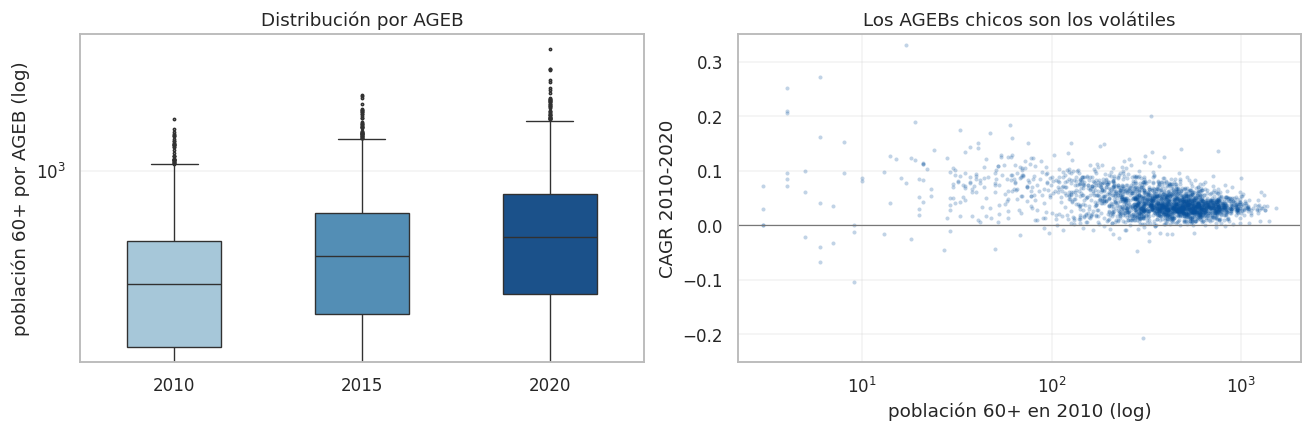

In [3]:
w = panel.pivot_table(index="cvegeo", columns="anio", values="p60").dropna()
w = w[(w > 0).all(axis=1)]
cagr = pd.DataFrame({f"{i}-{f}": (w[f]/w[i])**(1/(f-i)) - 1
                     for i, f in [(2010, 2015), (2015, 2020), (2010, 2020)]})
print(cagr.describe(percentiles=[.05, .5, .95]).round(3).to_string())
c = stats.spearmanr(w[2010], cagr["2010-2020"].abs())
print(f"\n|CAGR 2010-2020| > 10% anual: {(cagr['2010-2020'].abs() > .10).mean():.1%}")
print(f"Spearman(tamaño 2010, |CAGR|) = {c.statistic:+.3f} (p={c.pvalue:.1e})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=panel, x="anio", y="p60", ax=ax[0], width=.5, linewidth=.9, fliersize=1.5,
            hue="anio", legend=False, palette=[CANIO[a] for a in (2010, 2015, 2020)])
ax[0].set(yscale="log", xlabel="", ylabel="población 60+ por AGEB (log)", title="Distribución por AGEB")
ax[1].scatter(w[2010], cagr["2010-2020"], s=7, alpha=.25, color="#08519C", lw=0)
ax[1].axhline(0, color="#777", lw=.8)
ax[1].set(xscale="log", ylim=(-.25, .35), xlabel="población 60+ en 2010 (log)",
          ylabel="CAGR 2010-2020", title="Los AGEBs chicos son los volátiles")
plt.tight_layout(); plt.show()

### 1.4 Cómo se distribuye en el territorio

Se une el panel con el marco geoestadístico. Detalle técnico que conviene no saltarse: con contigüidad
Queen el grafo de vecindades tiene 5 componentes conexas —manchas urbanas desconectadas— y un AGEB
isla; hay que repararlo con `attach_islands` o cualquier algoritmo espacial falla.

cruce con la cartografía: 2,426 de 2,433 AGEBs


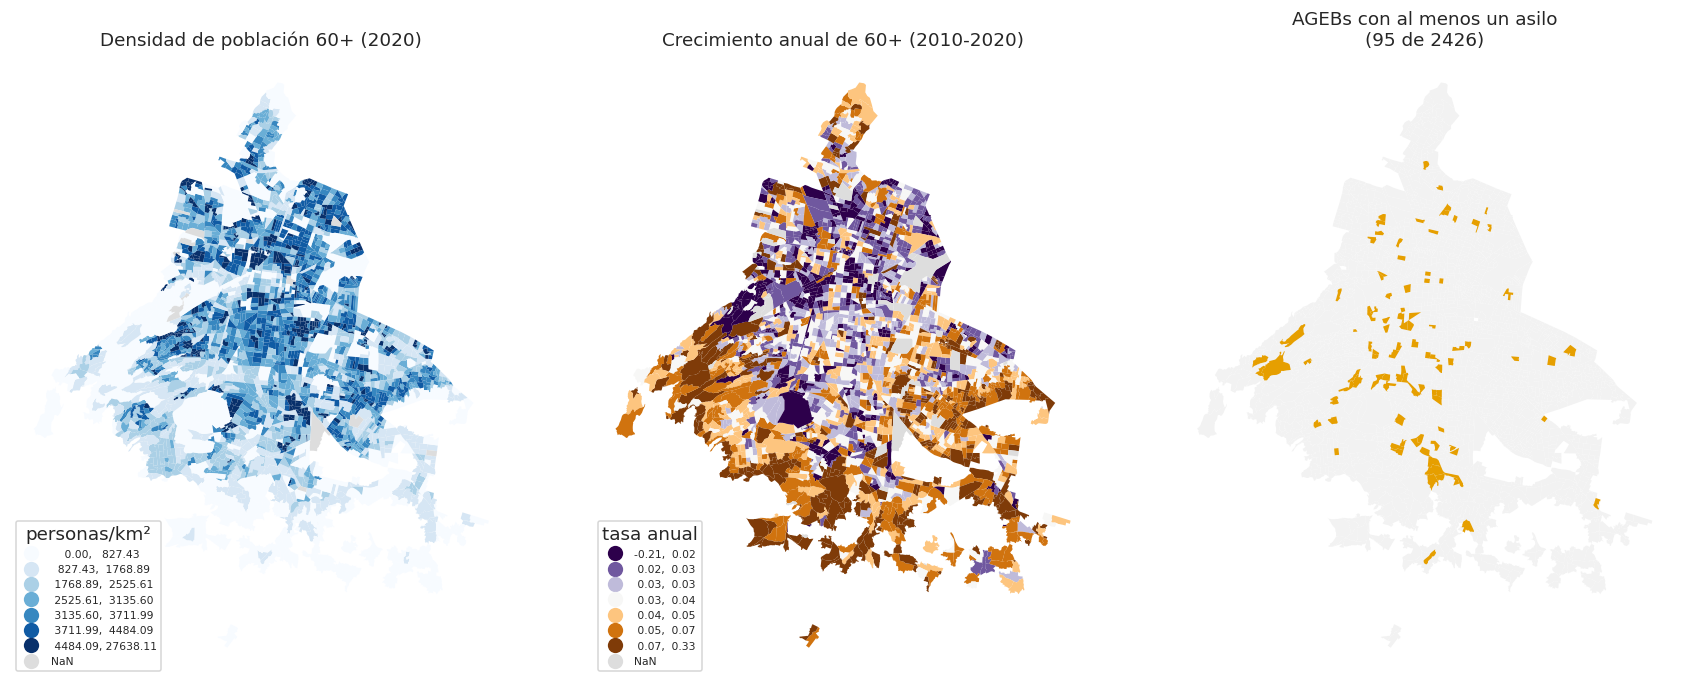

In [4]:
geo = gpd.read_file(SHAPEFILE)[["CVEGEO", "geometry"]].rename(columns={"CVEGEO": "cvegeo"})
anchos = panel.pivot_table(index="cvegeo", columns="anio", values="p60")
anchos.columns = [f"p60_{c}" for c in anchos.columns]
gg = (geo.merge(anchos, on="cvegeo", how="inner")
         .merge(ult[["cvegeo", "nom_mun"] + SERV], on="cvegeo", how="left")).reset_index(drop=True)
gg["area_km2"] = gg.area/1e6
gg["dens60"] = gg.p60_2020/gg.area_km2
gg["cagr"] = np.where((gg.p60_2010 > 0) & (gg.p60_2020 > 0), (gg.p60_2020/gg.p60_2010)**.1 - 1, np.nan)
print(f"cruce con la cartografía: {len(gg):,} de {ult.cvegeo.nunique():,} AGEBs")

fig, ax = plt.subplots(1, 3, figsize=(16, 6.2))
gg.plot(column="dens60", scheme="quantiles", k=7, cmap="Blues", ax=ax[0], legend=True,
        edgecolor="none", missing_kwds={"color": "#DDD"},
        legend_kwds={"fontsize": 7, "loc": "lower left", "title": "personas/km²"})
ax[0].set_title("Densidad de población 60+ (2020)")
gg.plot(column="cagr", scheme="quantiles", k=7, cmap="PuOr_r", ax=ax[1], legend=True,
        edgecolor="none", missing_kwds={"color": "#DDD"},
        legend_kwds={"fontsize": 7, "loc": "lower left", "title": "tasa anual"})
ax[1].set_title("Crecimiento anual de 60+ (2010-2020)")
gg.plot(color="#F2F2F2", edgecolor="white", linewidth=.05, ax=ax[2])
con_asilo = gg[gg.cantidad_asilos > 0]
con_asilo.plot(ax=ax[2], color="#E69F00", edgecolor="none")
ax[2].set_title(f"AGEBs con al menos un asilo\n({len(con_asilo)} de {len(gg)})")
for a_ in ax: a_.set_axis_off()
plt.tight_layout(); plt.savefig(FIG/"poblacion_y_oferta.png", dpi=150, bbox_inches="tight"); plt.show()

El contraste ya se ve a simple vista: la densidad de población mayor es alta en la ciudad central, pero
**el crecimiento está en la periferia** —los tonos oscuros del mapa de en medio, en el sur y poniente—
y los asilos del tercer mapa se concentran justo donde la población ya está, no donde va a estar.

### 1.5 ¿Es un patrón o es ruido? Autocorrelación espacial

La impresión visual hay que formalizarla. La **I de Moran** mide si los valores parecidos se agrupan en
el espacio: 0 es aleatorio, positivo es agrupado. El **LISA** hace lo mismo AGEB por AGEB e identifica
manchas Alto-Alto y Bajo-Bajo.

In [5]:
from libpysal.weights import Queen, KNN
from libpysal.weights.util import attach_islands
from esda.moran import Moran, Moran_Local

def pesos(s):
    w_ = attach_islands(Queen.from_dataframe(s, use_index=False), KNN.from_dataframe(s, k=1))
    w_.transform = "r"
    return w_

def moran_global(var, k=None):
    s = gg[np.isfinite(gg[var])].reset_index(drop=True)
    if k:
        w_ = KNN.from_dataframe(s, k=k); w_.transform = "r"
    else:
        w_ = pesos(s)
    mi = Moran(s[var].values.astype(float), w_, permutations=999)
    return dict(variable=var, pesos=f"KNN{k}" if k else "Queen", I=round(mi.I, 4),
                z=round(mi.z_sim, 2), p=mi.p_sim)

print(pd.DataFrame([moran_global(v, k) for v in ["dens60", "cagr", "cantidad_asilos",
                                                 "cantidad_serv_enf_dom"]
                    for k in (None, 6)]).to_string(index=False))

             variable pesos       I     z     p
               dens60 Queen  0.4469 37.19 0.001
               dens60  KNN6  0.4746 43.01 0.001
                 cagr Queen  0.3350 27.17 0.001
                 cagr  KNN6  0.3427 31.25 0.001
      cantidad_asilos Queen  0.0733  5.95 0.001
      cantidad_asilos  KNN6  0.0721  6.75 0.001
cantidad_serv_enf_dom Queen -0.0046 -0.34 0.363
cantidad_serv_enf_dom  KNN6 -0.0051 -0.43 0.301


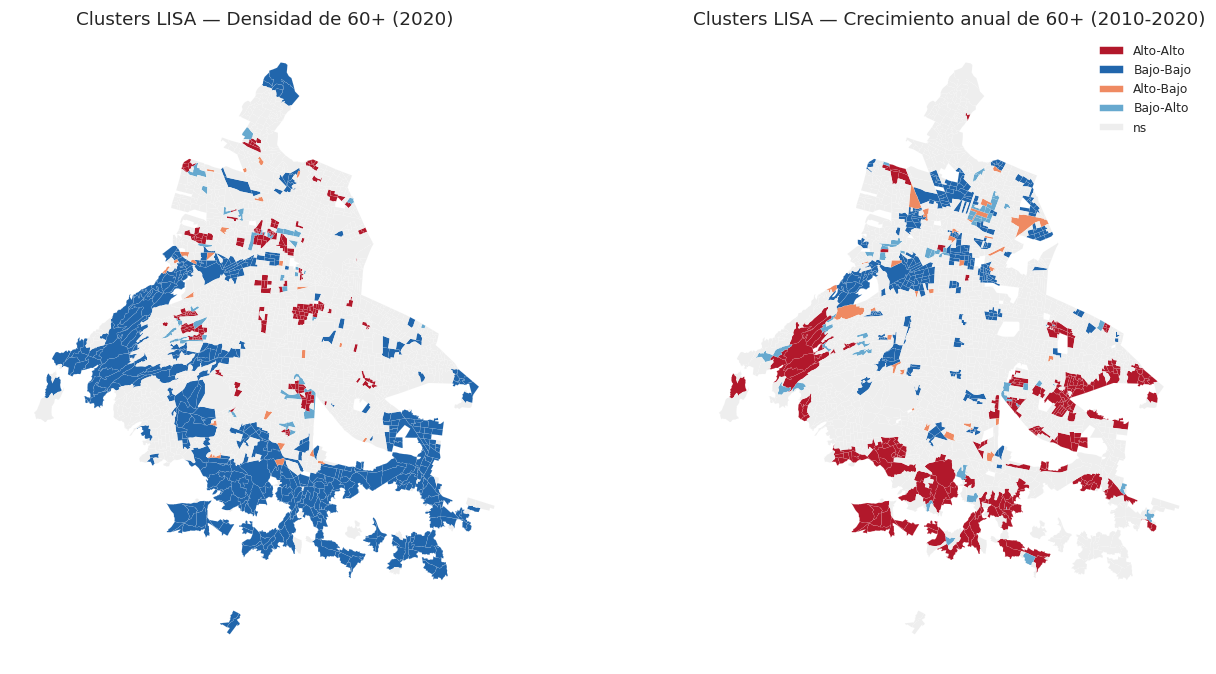

In [6]:
def lisa(var):
    s = gg[np.isfinite(gg[var])].reset_index(drop=True).copy()
    li = Moran_Local(s[var].values.astype(float), pesos(s), permutations=999, seed=SEMILLA)
    s["lisa"] = np.where(li.p_sim < .05, pd.Series(li.q).map(
        {1: "Alto-Alto", 2: "Bajo-Alto", 3: "Bajo-Bajo", 4: "Alto-Bajo"}), "ns")
    return s

COL_LISA = {"Alto-Alto": "#B2182B", "Bajo-Bajo": "#2166AC", "Alto-Bajo": "#EF8A62",
            "Bajo-Alto": "#67A9CF", "ns": "#EEEEEE"}
fig, ax = plt.subplots(1, 2, figsize=(13.5, 6.2))
for a_, (v, t) in zip(ax, [("dens60", "Densidad de 60+ (2020)"),
                           ("cagr", "Crecimiento anual de 60+ (2010-2020)")]):
    s = lisa(v)
    for k, col in COL_LISA.items():
        sub = s[s.lisa == k]
        if len(sub): sub.plot(ax=a_, color=col, edgecolor="white", linewidth=.05)
    a_.set_title(f"Clusters LISA — {t}"); a_.set_axis_off()
ax[1].legend(handles=[Patch(facecolor=c, label=k) for k, c in COL_LISA.items()],
             loc="upper right", frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG/"lisa.png", dpi=150, bbox_inches="tight"); plt.show()

Tres lecturas, y las tres importan más adelante:

- La población y su crecimiento tienen autocorrelación espacial **fuerte** (I ≈ 0.34-0.45), idéntica con
  Queen o con KNN(6), así que no es artefacto de cómo se definen los vecinos.
- Los asilos, **débil pero significativa** (I ≈ 0.07): se agrupan, pero mucho menos que la población.
- La enfermería a domicilio es **indistinguible de ruido aleatorio** (I = −0.005, p = 0.37). Tercera
  confirmación independiente de que ahí no hay nada que modelar.

El mapa del LISA es el hallazgo territorial: **clusters Alto-Alto de crecimiento en la periferia sur y
poniente** (Tlalpan, Xochimilco, Milpa Alta, Cuajimalpa) y **Bajo-Bajo en la ciudad central**. El
envejecimiento no crece donde ya hay más adultos mayores, sino en los bordes — que es donde hoy casi no
hay oferta.

## 2. Proyección de población

Con tres puntos en el tiempo no hay serie que extrapolar por AGEB, así que la pregunta real es **qué
tasa de crecimiento aplicarle a cada uno**. Y eso se decide con evidencia, no por gusto: backtest usando
2010 y 2015 para predecir 2020, que es el único año que se puede verificar.

In [7]:
mun_de = ult.set_index("cvegeo").nom_mun
real = w[2020]
tot = pd.DataFrame({"mun": mun_de}).join(w).dropna().groupby("mun")[[2010, 2015, 2020]].sum()
r_ageb = (w[2015]/w[2010])**.2 - 1                                            # tasa propia del AGEB
r_alc = w.index.to_series().map(mun_de).map((tot[2015]/tot[2010])**.2 - 1)    # tasa de su alcaldía

def error(pred, nombre):
    e, ape = pred - real, np.abs(pred - real)/real
    return dict(metodo=nombre, MALE=np.mean(np.abs(np.log(pred/real))), MAPE=100*np.median(ape),
                RMSE=np.sqrt(np.mean(e**2)), R2=1 - np.sum(e**2)/np.sum((real - real.mean())**2))

share15 = w[2015]/w.index.to_series().map(mun_de).map(tot[2015])
print(pd.DataFrame([
    error(w[2015]*(1 + .5*r_ageb + .5*r_alc)**5, "CAGR encogido 50% a la alcaldía"),
    error(w[2015]*(1 + r_ageb)**5, "CAGR propio del AGEB"),
    error(share15*w.index.to_series().map(mun_de).map(tot[2015]*(1 + (tot[2015]/tot[2010])**.2 - 1)**5),
          "Razón (share × total alcaldía)"),
    error(w[2015].astype(float), "Sin cambio (ingenuo)"),
]).set_index("metodo").round(3).to_string())

barrido = pd.DataFrame([{**error(w[2015]*(1 + lam*r_ageb + (1 - lam)*r_alc)**5, lam)}
                        for lam in np.arange(0, 1.01, .1)]).set_index("metodo")
print(f"\nλ óptimo por RMSE: {barrido.RMSE.idxmin():.1f} (curva plana entre 0.5 y 0.7)")

                                  MALE    MAPE     RMSE     R2
metodo                                                        
CAGR encogido 50% a la alcaldía  0.103  10.074   85.844  0.941
CAGR propio del AGEB             0.107  11.527   95.941  0.926
Razón (share × total alcaldía)   0.124  11.699  102.039  0.917
Sin cambio (ingenuo)             0.173  13.955  121.404  0.882

λ óptimo por RMSE: 0.6 (curva plana entre 0.5 y 0.7)


**Gana el encogimiento** (MAPE 10.1% contra 11.5% del CAGR propio, RMSE 86 contra 96), con R² de 0.94.
La fórmula es simplemente mezclar las dos tasas:

$$r_i = \lambda \, r_i^{\text{AGEB}} + (1-\lambda) \, r_{j(i)}^{\text{alcaldía}}$$

El λ óptimo es 0.6 y la curva es plana entre 0.5 y 0.7: **lo que importa es encoger algo, no el valor
exacto**. Funciona porque los AGEBs chicos tienen tasas volátiles por puro ruido de conteo (el Spearman
−0.345 de la sección 1.3), y mezclarlas con la tasa de su alcaldía las estabiliza sin sesgar las de los
AGEBs grandes, que tienen suficiente población para que su propia tasa sea informativa.

**Advertencia:** todos los métodos sobreestiman 2020 porque el crecimiento se desaceleró entre
quinquenios. Por eso se construyen tres escenarios en vez de un número. Lo ideal sería anclar los
totales por alcaldía a las proyecciones de CONAPO; aquí se usan tasas observadas como sustituto.

In [8]:
r_rec, r_full = (w[2020]/w[2015])**.2 - 1, (w[2020]/w[2010])**.1 - 1
ra = w.index.to_series().map(mun_de)
ra_rec, ra_full = ra.map((tot[2020]/tot[2015])**.2 - 1), ra.map((tot[2020]/tot[2010])**.1 - 1)
ESCENARIOS = {"bajo":  .5*r_rec + .5*ra_rec,                          # solo el quinquenio reciente
              "medio": .25*(r_rec + r_full) + .25*(ra_rec + ra_full), # mezcla
              "alto":  .5*r_full + .5*ra_full}                        # la década completa

proy = pd.DataFrame({e: [w[2020].sum()] + [(w[2020]*(1 + r)**h).sum() for h in (7, 9, 11)]
                     for e, r in ESCENARIOS.items()}, index=[2020, 2027, 2029, 2031])
print("Población de 60 y más proyectada (miles):")
print((proy/1000).round(0).to_string())
print("\ncrecimiento 2020→2031:",
      {e: f"{100*(proy.loc[2031, e]/proy.loc[2020, e] - 1):.1f}%" for e in ESCENARIOS})

pm_ = pd.DataFrame({"mun": mun_de, "p2020": w[2020],
                    "p2031": w[2020]*(1 + ESCENARIOS["medio"])**11}).groupby("mun").sum()/1000
pm_["cambio_%"] = (100*(pm_.p2031/pm_.p2020 - 1)).round(1)
print("\nPor alcaldía, escenario medio (miles de personas):")
print(pm_.sort_values("cambio_%", ascending=False).round(1).to_string())

Población de 60 y más proyectada (miles):
        bajo   medio    alto
2020  1487.0  1487.0  1487.0
2027  1865.0  1924.0  1986.0
2029  1993.0  2074.0  2161.0
2031  2132.0  2238.0  2353.0

crecimiento 2020→2031: {'bajo': '43.4%', 'medio': '50.6%', 'alto': '58.3%'}

Por alcaldía, escenario medio (miles de personas):
                        p2020  p2031  cambio_%
mun                                           
Cuajimalpa de Morelos    25.5   50.9      99.8
Milpa Alta               14.7   27.2      84.6
Tláhuac                  45.7   81.2      77.8
Xochimilco               60.0  104.2      73.7
Tlalpan                 107.5  177.3      64.9
La Magdalena Contreras   38.0   61.9      62.9
Iztapalapa              262.1  410.2      56.5
Álvaro Obregón          122.3  191.3      56.4
Iztacalco                70.9  107.4      51.4
Miguel Hidalgo           71.1  103.9      46.1
Coyoacán                126.6  184.3      45.6
Azcapotzalco             78.6  111.8      42.1
Venustiano Carranza      7

El patrón del LISA reaparece en las cifras: **Cuajimalpa +100%, Milpa Alta +85%, Tláhuac +78%** contra
+35% en Cuauhtémoc y +35% en Benito Juárez. El envejecimiento se está mudando a la periferia, y este es el insumo que alimenta tanto
el modelo de conteo como el análisis territorial.

## 3. ¿Cuántos asilos habrá?

Antes de entrar, conviene dejar claros los papeles, porque se ajustan dos modelos y hacen cosas
distintas:

| | modelo | papel en el análisis |
|---|---|---|
| **El que da la cifra** | **Binomial negativa** (§3.1) | Produce el total proyectado y su intervalo. Es el número que se reporta. |
| **La verificación** | **Jerárquico por regiones** (§3.2) | Vuelve a estimar el mismo total por un camino independiente, y además estima la estructura territorial que se usa en la sección 4. |
| Descartado | Poisson simple | Subestima la varianza y produce intervalos falsamente angostos. La comparación está en §3.5. |

**El modelo principal es una binomial negativa**, no una Poisson. La confusión es fácil porque la
binomial negativa *es* una Poisson con un parámetro extra de dispersión, y porque el jerárquico usa
verosimilitud Poisson — pero la cifra que sale de este análisis viene de la binomial negativa, y la
sección 3.5 muestra con números por qué la Poisson simple no serviría.

### 3.1 El modelo que da la cifra: binomial negativa sobre los seis cortes

$$\log \mu_{it} = \alpha + \beta \log(\text{pob60}_{it}) + \gamma \log(\text{área}_i) + \tau_t$$

Se ajusta **a nivel AGEB** —la máxima resolución, y la que mejor predice de todas las probadas— y
**sobre los seis cortes del DENUE a la vez**, no solo sobre 2020. Cada fila del panel es un par
(AGEB, corte): 2,396 × 6 ≈ 14 mil observaciones con 568 asilos-corte, contra las 2,396 filas y 108
asilos de una sola sección transversal.

Cuatro decisiones de especificación, cada una con su razón:

- **`log(área)` entra.** Sin ella la elasticidad sale inflada porque absorbe el efecto mecánico de que
  los AGEBs grandes albergan más establecimientos.
- **Sobredispersión sí, y no es un detalle.** El índice varianza/media del panel es 1.26: los datos
  varían más de lo que una Poisson permite. El AIC lo confirma (4,615 contra 4,751 de la Poisson). Y lo
  que está en juego no es el número sino el intervalo: proyectando con Poisson el total para 2031 sale
  prácticamente igual (123 contra 124) pero con un intervalo **14% más angosto**, y ese intervalo
  angosto sería falso — angosto porque el modelo asumió menos varianza de la que hay, no porque
  sepamos más.
- **Un efecto fijo por corte, $\tau_t$.** Es la pieza que hace honesto el panel. Absorbe las
  diferencias de nivel entre extracciones del DENUE —el salto de 2018 a 2020, la quietud de 2020 a
  2023— para que no se confundan con respuesta a la población. Sin él, el modelo leería como
  crecimiento de mercado lo que puede ser recodificación.
- **Errores estándar agrupados por AGEB.** Los seis cortes no son seis observaciones independientes:
  en buena medida son los mismos establecimientos medidos otra vez. Tratarlos como independientes
  daría intervalos falsamente angostos, exactamente el error que se critica a la Poisson en 3.5. El
  agrupamiento (*cluster*) por AGEB corrige eso.

Para las poblaciones de 2018, 2023 y 2025 —cortes sin censo— se usa el mismo método de la sección 2.
Eso introduce error de medición en el regresor, que atenúa β levemente hacia cero; es el precio de usar
los cortes, y conviene tenerlo presente al leer el coeficiente.

β sigue siendo una **elasticidad**: el porcentaje en que crece la oferta esperada cuando la población
crece 1%.

In [9]:
# ---- panel largo: un renglón por (AGEB, corte) --------------------------------
mod = gg[(gg.p60_2020 > 0) & gg.p60_2020.notna() & gg.nom_mun.notna()].reset_index(drop=True).copy()
mod["asilos"] = mod.cantidad_asilos.fillna(0).astype(int)          # oferta 2020, para referencia
mod["asilos_2025"] = mod.cvegeo.map(ofer[2025]).fillna(0).astype(int)
mod["lp60"], mod["larea"] = np.log(mod.p60_2020), np.log(mod.area_km2)

# población por AGEB en cada corte: observada en 2010/2015/2020, estimada en los demás
POB = pd.DataFrame(index=mod.cvegeo)
POB[2010], POB[2015], POB[2020] = mod.p60_2010.values, mod.p60_2015.values, mod.p60_2020.values
POB[2018] = POB[2015]*(POB[2020]/POB[2015])**(3/5)                 # interpolación geométrica
r_med = mod.cvegeo.map(ESCENARIOS["medio"]).fillna(0).values
POB[2023], POB[2025] = POB[2020].values*(1 + r_med)**3, POB[2020].values*(1 + r_med)**5
POB = POB[ANIOS_OF]

pnl = pd.concat([pd.DataFrame({
    "cvegeo": mod.cvegeo, "anio": a, "asilos": mod.cvegeo.map(ofer[a]).fillna(0).astype(int).values,
    "p60": POB[a].values, "area_km2": mod.area_km2.values, "nom_mun": mod.nom_mun.values})
    for a in ANIOS_OF], ignore_index=True)
pnl = pnl[pnl.p60 > 0].copy()
pnl["lp60"], pnl["larea"] = np.log(pnl.p60), np.log(pnl.area_km2)
print(f"panel: {len(pnl):,} filas ({pnl.cvegeo.nunique():,} AGEBs × {len(ANIOS_OF)} cortes) | "
      f"{pnl.asilos.sum():.0f} asilos-corte\n")

# ---- ajuste --------------------------------------------------------------------
FORM = "asilos ~ lp60 + larea + C(anio)"
pois_area = smf.glm(FORM, pnl, family=sm.families.Poisson()).fit()
mu0 = pois_area.fittedvalues
aux = sm.OLS(((pnl.asilos - mu0)**2 - pnl.asilos)/mu0, mu0).fit()
ALPHA = max(float(aux.params.iloc[0]), 1e-3)
nb = smf.glm(FORM, pnl, family=sm.families.NegativeBinomial(alpha=ALPHA)).fit(
    cov_type="cluster", cov_kwds={"groups": pnl.cvegeo})

print(f"alpha (Cameron-Trivedi) = {ALPHA:.3f}")
res = pd.DataFrame({"coef": nb.params, "EE_cluster": nb.bse,
                    "IC_lo": nb.params - 1.96*nb.bse, "IC_hi": nb.params + 1.96*nb.bse,
                    "p": nb.pvalues})
print(res.round(3).to_string())

solo20 = pnl[pnl.anio == 2020]
nb20 = smf.glm("asilos ~ lp60 + larea", solo20,
               family=sm.families.NegativeBinomial(alpha=3.385)).fit()
print(f"\nContraste — β con un solo corte (2020): {nb20.params['lp60']:.3f} ± {nb20.bse['lp60']:.3f}")
print(f"           β con los seis cortes       : {nb.params['lp60']:.3f} ± {nb.bse['lp60']:.3f}")

panel: 14,366 filas (2,396 AGEBs × 6 cortes) | 568 asilos-corte



alpha (Cameron-Trivedi) = 4.759
                  coef  EE_cluster  IC_lo  IC_hi      p
Intercept       -5.817       1.346 -8.454 -3.179  0.000
C(anio)[T.2015] -0.120       0.107 -0.331  0.090  0.263
C(anio)[T.2018] -0.075       0.113 -0.298  0.147  0.505
C(anio)[T.2020]  0.094       0.125 -0.151  0.338  0.454
C(anio)[T.2023]  0.037       0.136 -0.230  0.304  0.785
C(anio)[T.2025]  0.003       0.151 -0.294  0.299  0.985
lp60             0.508       0.208  0.101  0.915  0.014
larea            0.478       0.095  0.291  0.665  0.000



Contraste — β con un solo corte (2020): 0.558 ± 0.182
           β con los seis cortes       : 0.508 ± 0.208


**La elasticidad es 0.51, con intervalo de 95% de [0.10, 0.92].** Por cada 10% más de población mayor,
la oferta esperada crece 5.1%. Que β sea menor que 1 es el resultado sustantivo del análisis: **la
brecha se ensancha sola con el tiempo**, sin que nada tenga que empeorar.

Dos cosas que vale la pena notar del contraste con la versión de un solo corte:

- **El coeficiente casi no se mueve** (0.558 con 2020 solo, 0.508 con los seis cortes). La relación
  entre población y oferta es estable a lo largo de quince años, y eso es una señal de que la
  especificación es razonable.
- **El intervalo ahora excluye β = 1**, aunque por poco. Con un solo corte no se podía distinguir 0.5
  de 1; con el panel sí, y eso convierte "la oferta responde menos que proporcionalmente" de conjetura
  plausible en resultado estadístico.

Los efectos por corte, $\tau_t$, no son ruido que sobra: son el registro de que los cortes del DENUE no
miden exactamente lo mismo. Dejarlos dentro del modelo es lo que impide que el salto de 2018-2020 se
lea como una expansión del mercado.

### 3.2 La verificación independiente: el modelo jerárquico

La binomial negativa da el total de la ciudad. El jerárquico responde otra cosa: **cuánta
heterogeneidad hay entre zonas que la población y el área no explican**, y cuánta propensión tiene cada
una.

$$y_{ij} \sim \text{Poisson}(\mu_{ij}), \quad
\log \mu_{ij} = \alpha_j + \beta \tilde{x}_{ij} + \gamma \tilde{a}_{ij}, \quad
\alpha_j = \mu_\alpha + \sigma_\alpha z_j$$

con $j$ el grupo territorial y parametrización no centrada, que es la que muestrea bien con pocos
grupos.

Los efectos fijos no sirven aquí: Venustiano Carranza y Milpa Alta tienen **cero** asilos, y un efecto
fijo les asignaría tasa cero o quedaría no identificado. El *partial pooling* les asigna una tasa baja
pero plausible, encogiéndolas hacia el promedio en proporción a lo poco que informan sus datos — la
misma idea que ya usamos para proyectar población en la sección 2.

**Con qué agrupar: está decidido con evidencia.** Se probaron seis niveles de agrupación, desde ninguna
hasta ~300 regiones, y se compararon con validación cruzada **espacial por bloques** —dejando fuera
bloques geográficos completos, que es más exigente que la validación aleatoria porque impide aprender
de los vecinos inmediatos del AGEB que se predice:

| agrupación | grupos | log-score (↑ mejor) | AUC | total predicho (obs. 27) |
|---|---|---|---|---|
| Alcaldía | 16 | −0.1857 | 0.610 | 25.6 |
| **Ward k=40** | **40** | **−0.1800** | **0.648** | **26.2** |
| Ward k=80 | 80 | −0.1810 | 0.642 | 26.7 |
| Ward k=150 | 150 | −0.1823 | 0.628 | 27.8 |
| Ward k=300 | 298 | −0.1819 | 0.623 | 26.4 |

**Gana Ward k=40**, y por eso es la agrupación que se usa aquí: mejor log-score, mejor AUC y mejor
calibración del total. Las regiones son agregados contiguos de AGEBs construidos con Ward restringido
por contigüidad sobre población y coordenadas — zonas con sentido geográfico, aunque sin frontera
administrativa.

Dos cosas que conviene no perder de vista:

- **El LOO se equivoca aquí.** Prefiere monótonamente lo más fino (−434.8 sin agrupar → −404.7 con 298
  grupos), o sea recomendaría casi un efecto por AGEB. Con efectos aleatorios espaciales, el LOO deja
  fuera una observación cuyo grupo sigue estimado por sus vecinos, así que premia el sobreajuste. La
  validación por bloques no tiene ese problema, y da un óptimo interior en 40.
- **La alcaldía se conserva como lectura, no como modelo.** Pierde contra Ward k=40 en predicción, pero
  es la única partición con significado administrativo, así que se ajusta también para poder decir algo
  sobre quién decide presupuesto. Se reportan las dos.

**Y este modelo no compite con la binomial negativa, la contiene.** Modelan la misma cantidad; la única
diferencia es que en la binomial negativa α es un número para toda la ciudad y en el jerárquico varía
por zona. Si σ_α fuera cero serían el mismo modelo. Lo que cambia es qué hace cada uno con la
sobredispersión: la binomial negativa la trata como ruido sin estructura y la mete en un parámetro de
dispersión (α ≈ 4.8); el jerárquico dice que parte de ese ruido no es ruido sino el territorio, y la
mete en los interceptos. Son dos lecturas del mismo exceso de variación. **La binomial negativa se usa
para el total —a nivel AGEB es el mejor predictor de todos los probados, estimado ahora sobre los seis cortes—; el
jerárquico, para la estructura territorial.**

In [10]:
import arviz as az
from sklearn.cluster import AgglomerativeClustering

# Regiones Ward k=40: agregados CONTIGUOS de AGEBs (la contigüidad se impone con el grafo Queen
# reparado como matriz de conectividad), sobre población y coordenadas estandarizadas.
s_ = gg.reset_index(drop=True)
W_ = pesos(s_)
XW = np.c_[s_.p60_2020.fillna(s_.p60_2020.median()).values,
           s_.geometry.centroid.x.values, s_.geometry.centroid.y.values]
XW = (XW - XW.mean(0))/XW.std(0)
lab = AgglomerativeClustering(n_clusters=40, connectivity=W_.sparse,
                              linkage="ward").fit_predict(XW)
REG = pd.Series([f"R{v:02d}" for v in lab], index=s_.cvegeo)
mod["region"] = mod.cvegeo.map(REG).values
pnl["region"] = pnl.cvegeo.map(REG).values
print(f"regiones Ward: {mod.region.nunique()} | AGEBs por región: "
      f"mediana {int(mod.region.value_counts().median())}, "
      f"rango [{mod.region.value_counts().min()}, {mod.region.value_counts().max()}]")

regiones Ward: 40 | AGEBs por región: mediana 50, rango [1, 172]


In [11]:
def ajustar_jerarquico(datos, col_grupo, S=6000, semilla=SEMILLA, verbose=True):
    # Intenta NUTS con PyMC; si no puede compilar (frecuente en macOS con Apple Silicon)
    # cae a la aproximación variacional de statsmodels, que no necesita compilador.
    # Ambas rutas devuelven un InferenceData con las mismas variables.
    xx = (datos.lp60 - datos.lp60.mean()).values
    aa = (datos.larea - datos.larea.mean()).values
    yy = datos.asilos.values
    idx, grupos = pd.factorize(datos[col_grupo])
    ia, anios_ = pd.factorize(datos.anio)              # efecto por corte del DENUE
    try:
        import pymc as pm, pytensor.tensor as pt
        with pm.Model(coords={"grupo": list(grupos), "corte": [str(a) for a in anios_]}):
            mu_a = pm.Normal("mu_alpha", -3.5, 2); sig_a = pm.HalfNormal("sigma_alpha", 1.)
            z = pm.Normal("z", 0, 1, dims="grupo")
            alpha = pm.Deterministic("alpha", mu_a + sig_a*z, dims="grupo")
            beta = pm.Normal("beta", 1., .5); gamma = pm.Normal("gamma", 0., .5)
            tau = pm.Normal("tau", 0, .5, dims="corte")
            pm.Poisson("y", mu=pt.exp(alpha[idx] + beta*xx + gamma*aa + tau[ia]), observed=yy)
            idata = pm.sample(1000, tune=1000, chains=4, cores=4, target_accept=.92,
                              random_seed=semilla, progressbar=False)
        if verbose: print(f"[{col_grupo}] ajustado con NUTS (PyMC).")
        return idata, grupos
    except Exception as e:
        if verbose:
            print(f"[{col_grupo}] PyMC no pudo compilar ({type(e).__name__}); "
                  "se usa la aproximación variacional.")
        from statsmodels.genmod.bayes_mixed_glm import PoissonBayesMixedGLM
        d_ = datos.assign(_x=xx, _a=aa, _g=datos[col_grupo].astype(str),
                          _t=datos.anio.astype(str))
        r = PoissonBayesMixedGLM.from_formula("asilos ~ _x + _a + C(_t)", {"g": "0 + C(_g)"},
                                              d_).fit_vb(verbose=False)
        rng_ = np.random.default_rng(semilla)
        mu_alpha = rng_.normal(r.fe_mean[0], r.fe_sd[0], S)
        nombres = list(r.model.exog_names)
        i_b, i_g = nombres.index("_x"), nombres.index("_a")
        beta = rng_.normal(r.fe_mean[i_b], r.fe_sd[i_b], S)
        gamma = rng_.normal(r.fe_mean[i_g], r.fe_sd[i_g], S)
        sigma = np.exp(rng_.normal(r.vcp_mean[0], r.vcp_sd[0], S))
        orden = sorted(d_._g.unique()); pos = {g: i for i, g in enumerate(orden)}
        re = np.array([rng_.normal(m_, s_) if np.isscalar(m_) else rng_.normal(m_, s_, S)
                       for m_, s_ in zip(r.vc_mean, r.vc_sd)])
        alpha = np.array([mu_alpha + re[pos[str(g)]] for g in grupos])
        idata = az.from_dict({"alpha": alpha.T[None, ...], "beta": beta[None, :],
                              "gamma": gamma[None, :], "mu_alpha": mu_alpha[None, :],
                              "sigma_alpha": sigma[None, :]},
                             coords={"grupo": [str(g) for g in grupos]},
                             dims={"alpha": ["grupo"]})
        return idata, grupos

idata, regs = ajustar_jerarquico(pnl, "region")          # el modelo elegido
idata_alc, muns = ajustar_jerarquico(pnl, "nom_mun")     # la lectura administrativa

print("\nWard k=40 (modelo elegido):")
print(az.summary(idata, var_names=["mu_alpha", "sigma_alpha", "beta", "gamma"]).round(3).to_string())
print("\nAlcaldía (lectura administrativa):")
print(az.summary(idata_alc, var_names=["mu_alpha", "sigma_alpha", "beta", "gamma"]).round(3).to_string())

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_alpha, sigma_alpha, z, beta, gamma, tau]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 101 seconds.


[region] ajustado con NUTS (PyMC).


...

Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_alpha, sigma_alpha, z, beta, gamma, tau]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 100 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


[nom_mun] ajustado con NUTS (PyMC).

Ward k=40 (modelo elegido):
              mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  r_hat
mu_alpha    -4.101  0.307  -4.673   -3.539      0.012    0.007     706.0    1231.0    1.0
sigma_alpha  1.191  0.186   0.859    1.534      0.007    0.003     770.0    1474.0    1.0
beta         0.572  0.093   0.396    0.742      0.001    0.001    4091.0    3132.0    1.0
gamma        0.549  0.062   0.433    0.664      0.001    0.001    4896.0    3193.0    1.0

Alcaldía (lectura administrativa):
              mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  r_hat
mu_alpha    -3.569  0.298  -4.108   -2.991      0.012    0.006     670.0    1216.0   1.01
sigma_alpha  0.805  0.186   0.502    1.169      0.006    0.004     898.0    1843.0   1.00
beta         0.392  0.068   0.266    0.522      0.001    0.001    2716.0    2351.0   1.00
gamma        0.404  0.066   0.280    0.528      0.001    0.001    3188.0    3033.0   1.00

**σ_α está claramente lejos de cero en las dos versiones**: hay heterogeneidad territorial real que ni
la población ni el área explican. Y es mayor con las regiones Ward (σ_α ≈ 1.19) que con alcaldías
(≈ 0.81), que es lo esperable — al agrupar más fino se capta estructura que la frontera administrativa
promedia y borra.

La elasticidad se mueve entre las dos (0.57 con regiones, 0.39 con alcaldías) y ambas caen dentro del
intervalo de la binomial negativa: **las tres especificaciones cuentan la misma historia**. Vale la
pena notar que con el panel de seis cortes el intervalo del jerárquico se estrecha a [0.40, 0.74] —
mucho más apretado que el [0.10, 0.92] de la binomial negativa con errores agrupados, porque el
jerárquico reparte parte de la variación entre las regiones en vez de dejarla toda en el término de
dispersión.

                        agebs  asilos     pob60  tasa_cruda_x1000  alpha  hdi_3%  hdi_97%  propension
nom_mun                                                                                              
Benito Juárez             102      14   87344.0             0.160 -2.250  -2.689   -1.824       0.105
Coyoacán                  156      16  126592.0             0.126 -2.889  -3.364   -2.489       0.056
La Magdalena Contreras     52       5   37979.0             0.132 -2.938  -3.516   -2.426       0.053
Cuauhtémoc                152       8   93807.0             0.085 -3.009  -3.473   -2.542       0.049
Xochimilco                119       9   60006.0             0.150 -3.053  -3.593   -2.617       0.047
Tlalpan                   205      13  107553.0             0.121 -3.199  -3.630   -2.724       0.041
Miguel Hidalgo            120       5   71107.0             0.070 -3.253  -3.800   -2.778       0.039
Azcapotzalco              102       6   78649.0             0.076 -3.325  -3.827  

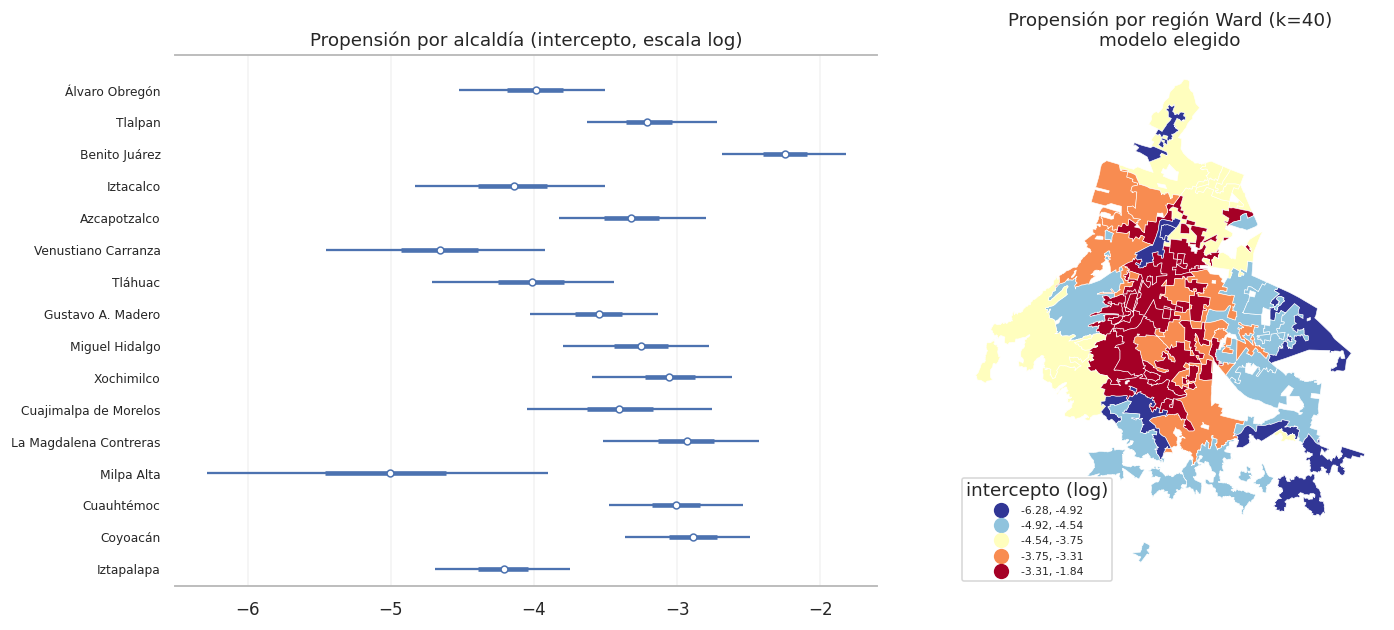

In [12]:
s = az.summary(idata_alc, var_names=["alpha"]); s.index = muns
comp = (mod.groupby("nom_mun").agg(agebs=("asilos", "size"), asilos=("asilos", "sum"),
                                   pob60=("p60_2020", "sum"))
        .join(s[["mean", "hdi_3%", "hdi_97%"]]).rename(columns={"mean": "alpha"}))
comp["tasa_cruda_x1000"] = 1000*comp.asilos/comp.pob60
comp["propension"] = np.exp(comp.alpha)   # asilos esperados en un AGEB promedio de esa alcaldía
print(comp[["agebs", "asilos", "pob60", "tasa_cruda_x1000", "alpha", "hdi_3%", "hdi_97%", "propension"]]
      .sort_values("alpha", ascending=False).round(3).to_string())
print("\nVenustiano Carranza y Milpa Alta tienen 0 asilos observados pero el modelo les asigna")
print("una propensión baja y no nula: eso es el partial pooling.")

fig, ax = plt.subplots(1, 2, figsize=(14, 5.8))
az.plot_forest(idata_alc, var_names=["alpha"], combined=True, ax=ax[0])
ax[0].set_yticklabels(list(muns)[::-1], fontsize=8)
ax[0].set_title("Propensión por alcaldía (intercepto, escala log)")

a_reg = az.summary(idata, var_names=["alpha"]); a_reg.index = regs
mapa_reg = mod[["region", "geometry"]].dissolve(by="region")
mapa_reg["alpha"] = a_reg["mean"]
mapa_reg.plot(column="alpha", cmap="RdYlBu_r", scheme="quantiles", k=5, ax=ax[1], legend=True,
              edgecolor="white", linewidth=.4,
              legend_kwds={"fontsize": 7, "loc": "lower left", "title": "intercepto (log)"})
ax[1].set_title("Propensión por región Ward (k=40)\nmodelo elegido"); ax[1].set_axis_off()
plt.tight_layout(); plt.savefig(FIG/"jerarquico.png", dpi=150, bbox_inches="tight"); plt.show()

El orden por alcaldía es inequívocamente socioeconómico: Benito Juárez y Coyoacán arriba, las
periféricas abajo. **Hoy hay más oferta de la que la población y el área explicarían en las zonas de
mayor ingreso** — ése es el enunciado que los datos sostienen. Conviene no estirarlo: es una
afirmación sobre el *nivel* actual, no sobre hacia dónde se está moviendo el mercado. La sección 4.2
muestra que la dinámica 2010-2025 no confirma ese movimiento en ninguna dirección. El mapa de las
regiones Ward dice lo mismo con más resolución.

> **Este mapa es la mitad del diagnóstico.** Contesta *dónde hay hoy más oferta de la que la población
> explicaría*. La otra mitad —*dónde se está sumando la demanda*— sale en la **sección 4**, y las dos
> se ponen frente a frente ahí. Conviene tenerlo presente al leer lo que sigue.

### 3.2.1 ¿Las regiones respetan las alcaldías?

No, y ahí está justamente la razón de que k=40 prediga mejor. Vale la pena verlo con las dos
particiones en la misma escala de color y las fronteras de alcaldía encima de las regiones.

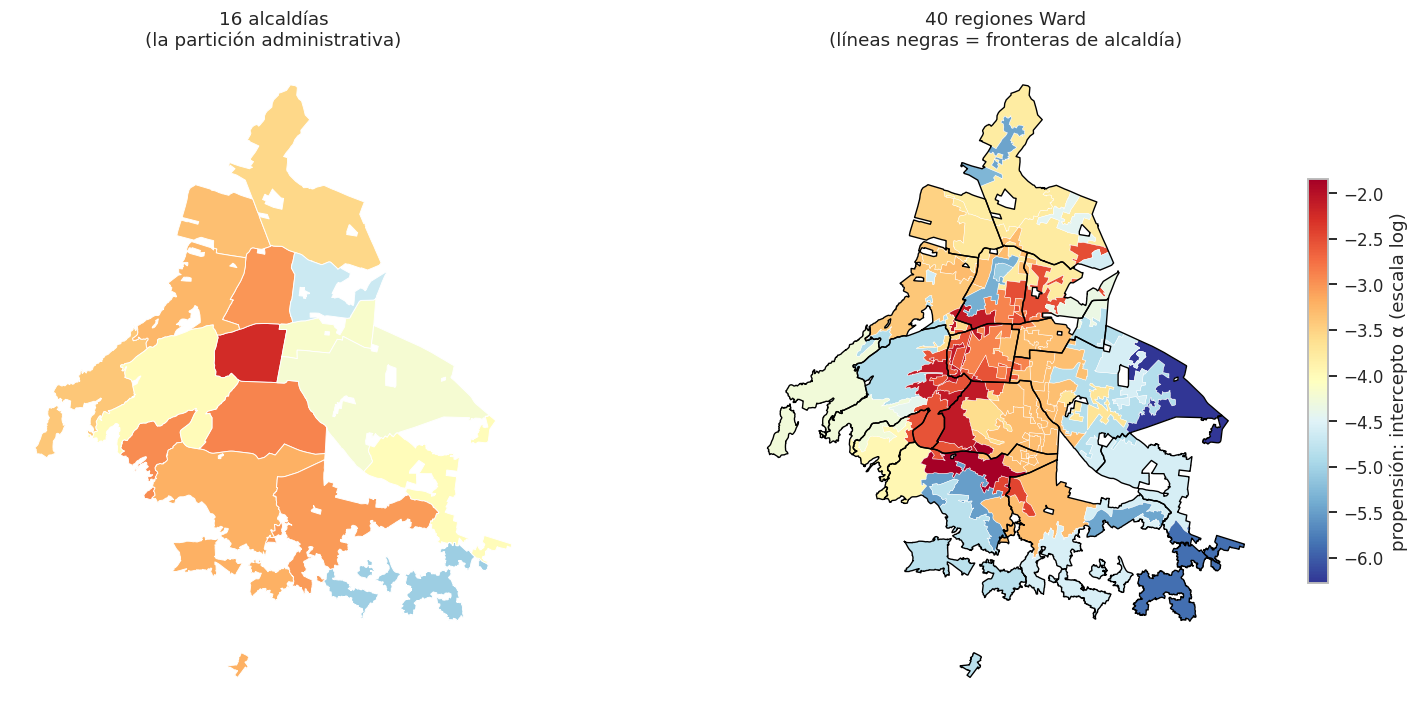

regiones que cruzan más de una alcaldía: 26 de 40

                        agebs  regiones  alpha_min  alpha_max  rango  alpha_alcaldia
nom_mun                                                                             
Iztapalapa                453        10      -6.28      -2.54   3.73           -4.22
Tlalpan                   205         8      -5.50      -1.84   3.66           -3.20
Cuauhtémoc                152         9      -5.37      -2.10   3.27           -3.01
Xochimilco                119         6      -5.44      -2.44   3.00           -3.05
Gustavo A. Madero         302         9      -5.46      -2.52   2.94           -3.55
Álvaro Obregón            197         7      -4.88      -2.10   2.78           -3.99
Miguel Hidalgo            120         9      -4.88      -2.10   2.78           -3.25
Iztacalco                 107         6      -4.86      -2.88   1.97           -4.15
Venustiano Carranza       147         5      -4.35      -2.52   1.84           -4.67
Coyoacán      

In [13]:
a_alc = az.summary(idata_alc, var_names=["alpha"])["mean"].values
mapa_alc = mod[["nom_mun", "geometry"]].dissolve(by="nom_mun")
mapa_alc["alpha"] = pd.Series(a_alc, index=muns)

vmin = min(mapa_reg.alpha.min(), mapa_alc.alpha.min())
vmax = max(mapa_reg.alpha.max(), mapa_alc.alpha.max())
fig, ax = plt.subplots(1, 2, figsize=(14.5, 6.6))
mapa_alc.plot(column="alpha", cmap="RdYlBu_r", vmin=vmin, vmax=vmax, ax=ax[0],
              edgecolor="white", linewidth=.6)
ax[0].set_title("16 alcaldías\n(la partición administrativa)")
mapa_reg.plot(column="alpha", cmap="RdYlBu_r", vmin=vmin, vmax=vmax, ax=ax[1],
              edgecolor="white", linewidth=.3, legend=True,
              legend_kwds={"shrink": .62, "label": "propensión: intercepto α (escala log)"})
mapa_alc.boundary.plot(ax=ax[1], color="black", linewidth=.9)
ax[1].set_title("40 regiones Ward\n(líneas negras = fronteras de alcaldía)")
for a_ in ax: a_.set_axis_off()
plt.tight_layout(); plt.savefig(FIG/"alcaldias_vs_regiones.png", dpi=150, bbox_inches="tight"); plt.show()

reg_alc = (mod.assign(a_reg=mod.region.map(pd.Series(a_reg["mean"].values, index=regs)))
              .groupby("nom_mun")
              .agg(agebs=("region", "size"), regiones=("region", "nunique"),
                   alpha_min=("a_reg", "min"), alpha_max=("a_reg", "max"))
              .assign(rango=lambda d: d.alpha_max - d.alpha_min)
              .join(mapa_alc.alpha.rename("alpha_alcaldia"))
              .sort_values("rango", ascending=False))
cruce = mod.groupby("region").nom_mun.nunique()
print(f"regiones que cruzan más de una alcaldía: {(cruce > 1).sum()} de {len(cruce)}\n")
print(reg_alc.round(2).to_string())

**Cómo se lee esta figura, que es donde aparece el resultado de la inferencia.**

El panel de la izquierda no muestra un número por alcaldía: muestra la **distribución posterior
completa** del intercepto de cada una. El punto es la media, la barra gruesa el 50% central y la
delgada el 94%. **El ancho de la barra es parte del resultado, no un adorno** — dice cuánta evidencia
hay detrás de cada estimación.

Cuatro cosas concretas que se ven ahí y que no se verían en una tabla de tasas crudas:

- **Benito Juárez arriba, con la barra más angosta:** α = −2.25, intervalo [−2.69, −1.82]. Tiene 102
  AGEBs y 14 asilos, así que el modelo la estima con precisión. Su propensión, exp(α), es 0.105 asilos
  esperados en un AGEB promedio.
- **Milpa Alta abajo, con la barra más ancha de todas:** α = −5.06, intervalo [−6.29, −3.90]. Tiene
  cero asilos observados, y aquí está la gracia del *partial pooling*: el modelo **no le asigna cero**
  —que sería absurdo y además rompería la escala logarítmica— sino una propensión baja y muy incierta.
  Con 42 AGEBs no hay con qué afinarla más. Venustiano Carranza también tiene cero asilos, pero con 147
  AGEBs su barra sale bastante más angosta: **más territorio observado sin un solo establecimiento es
  más evidencia de que la tasa es realmente baja.**
- **El encogimiento en acción:** Cuajimalpa tiene la **tasa cruda más alta de la ciudad** (0.196 asilos
  por cada mil personas de 60+), pero en el modelo queda a media tabla. Son 5 asilos en 31 AGEBs —
  evidencia delgada— así que se jala hacia el promedio de la ciudad. Eso es exactamente lo que uno
  quiere: que una tasa alta calculada sobre pocos casos no se tome al pie de la letra.
- **Y la advertencia:** casi todas las barras se traslapan. Lo que la figura autoriza a decir es que
  **Benito Juárez está por encima del grupo de abajo** —Iztapalapa, Iztacalco, Venustiano Carranza,
  Milpa Alta— pero **no** a ordenar con confianza las alcaldías del medio entre sí.

Los dos mapas son la misma cantidad, en la misma escala de color, sobre dos particiones distintas. El
de en medio pinta cada alcaldía con su intercepto; el de la derecha, cada una de las 40 regiones Ward,
con las fronteras de alcaldía encima en negro para poder comparar.

**La comparación es el argumento de la sección.** La mancha roja del mapa derecho —las zonas de mayor
propensión— atraviesa en diagonal las fronteras negras sin respetarlas: **26 de las 40 regiones cruzan
más de una alcaldía**. Y el contraste interno es enorme donde el promedio administrativo lo escondía:
dentro de Iztapalapa los interceptos de sus diez regiones van de −6.28 a −2.54, un rango de 3.73 en
escala logarítmica, que son **más de 40 veces** de diferencia en propensión entre su zona más y menos
dotada. Azcapotzalco, en cambio, es casi homogénea (rango de 0.29, apenas 1.3 veces).

Por eso k=40 predice mejor que 16, y no por tener más parámetros: **los límites caen donde de verdad
cambia el comportamiento del mercado** —el borde entre colonia consolidada y periferia— en lugar de
donde lo decidió la geografía política. Y por eso la alcaldía se conserva como lectura: el presupuesto
se decide por alcaldía aunque el mercado no se comporte así.

### 3.3 Proyección a 2026, 2027, 2029 y 2031

Se aplica la binomial negativa a la población proyectada de la sección 2, propagando dos fuentes de
incertidumbre: la de los parámetros (intervalo `par_`, muestreando de la distribución de los
coeficientes) y además la variación muestral del propio conteo (intervalo `pred_`, que es el relevante
para pronosticar porque un conteo es aleatorio aunque se conozca μ perfectamente).

**El ancla es el último corte.** La proyección se hace manteniendo el efecto del corte de 2025, o sea
partiendo del nivel realmente observado ese año y dejando que la población sea lo único que mueva la
cifra hacia adelante. Eso tiene dos virtudes: el modelo queda calibrado contra el dato más reciente
—la celda imprime la verificación— y el horizonte de extrapolación baja de once años a seis.

**Qué es y qué no es:** es la oferta esperada **si el mercado sigue comportándose como hasta ahora**. No
es una estimación de necesidad.

In [14]:
rng = np.random.default_rng(SEMILLA); S = 8000
coefs = rng.multivariate_normal(nb.params.values, nb.cov_params().values, S)
n_r = 1/ALPHA
NOM = list(nb.params.index)
i_int, i_p, i_a = NOM.index("Intercept"), NOM.index("lp60"), NOM.index("larea")
i_ult = NOM.index(f"C(anio)[T.{ANIOS_OF[-1]}]")     # se proyecta desde el nivel del último corte
larea_v = mod.larea.values
ANIOS_PRED = [(2026, 6), (2027, 7), (2029, 9), (2031, 11)]

def proyectar(esc, h):
    p_fut = mod.p60_2020.values*(1 + mod.cvegeo.map(ESCENARIOS[esc]).fillna(0).values)**h
    lin = (coefs[:, i_int][None, :] + coefs[:, i_p][None, :]*np.log(p_fut)[:, None]
           + coefs[:, i_a][None, :]*larea_v[:, None] + coefs[:, i_ult][None, :])
    mu = np.exp(lin)
    return p_fut, mu.sum(axis=0), rng.negative_binomial(n_r, n_r/(n_r + mu)).sum(axis=0)

filas = []
for esc in ESCENARIOS:
    for anio, h in ANIOS_PRED:
        p_fut, tot_par, tot_pred = proyectar(esc, h)
        filas.append(dict(escenario=esc, anio=anio, pob60=p_fut.sum(), esperados=tot_par.mean(),
                          par_lo=np.percentile(tot_par, 5), par_hi=np.percentile(tot_par, 95),
                          pred_lo=np.percentile(tot_pred, 5), pred_hi=np.percentile(tot_pred, 95)))
print(pd.DataFrame(filas).round(1).to_string(index=False))

# calibración: el modelo reproducido sobre el último corte observado
_, ajuste25, _ = proyectar("medio", 5)
print(f"\nCalibración — ajuste para {ANIOS_OF[-1]}: {ajuste25.mean():.0f} asilos "
      f"contra {ofer[ANIOS_OF[-1]].sum():.0f} observados")

p31, _, tp = proyectar("medio", 11)
A_HOY = ofer[ANIOS_OF[-1]].sum()
print(f"P(total 2031 > {A_HOY:.0f}, el nivel de hoy) = {(tp > A_HOY).mean():.3f}")

# ¿de dónde viene la incertidumbre? varianza del total con cada fuente por separado
def mu_fija(p_fut, c):
    return np.exp(c[i_int] + c[i_p]*np.log(p_fut) + c[i_a]*larea_v + c[i_ult]).sum()
v_par = np.var([mu_fija(p31, c) for c in coefs[:2000]])
v_tot = np.var(tp.astype(float))
v_esc = np.var([mu_fija(mod.p60_2020.values*(1 + mod.cvegeo.map(ESCENARIOS[e]).fillna(0).values)**11,
                        nb.params.values) for e in ESCENARIOS])

# cruce: la misma proyección con el jerárquico (Ward k=40)
post = idata.posterior
al = post.alpha.stack(m=("chain", "draw")).values
be = post.beta.stack(m=("chain", "draw")).values
ga = post.gamma.stack(m=("chain", "draw")).values
ta = post.tau.stack(m=("chain", "draw")).values[list(pd.factorize(pnl.anio)[1]).index(ANIOS_OF[-1])]
gi = pd.factorize(mod.region)[0]
xc = np.log(p31) - pnl.lp60.mean()
ac = larea_v - pnl.larea.mean()
mu_j = np.exp(al[gi] + be[None, :]*xc[:, None] + ga[None, :]*ac[:, None] + ta[None, :])
tot_j = rng.poisson(mu_j).sum(axis=0)
print(f"\nJerárquico (Ward k=40) para 2031: {tot_j.mean():.0f} asilos "
      f"[{np.percentile(tot_j, 5):.0f}, {np.percentile(tot_j, 95):.0f}]")
print(f"Binomial negativa para 2031    : {tp.mean():.0f} asilos "
      f"[{np.percentile(tp, 5):.0f}, {np.percentile(tp, 95):.0f}]")

print(f"\nDescomposición de la varianza del total 2031:")
print(f"  parámetros del modelo : {100*v_par/v_tot:.0f}%")
print(f"  aleatoriedad del conteo: {100*(v_tot - v_par)/v_tot:.0f}%")
print(f"  escenario demográfico  : {100*v_esc/v_tot:.0f}%")

escenario  anio     pob60  esperados  par_lo  par_hi  pred_lo  pred_hi
     bajo  2026 1804177.8      110.8    92.5   131.5     84.0    140.0
     bajo  2027 1864615.5      112.7    94.2   133.8     86.0    142.0
     bajo  2029 1992838.2      116.8    97.6   139.2     90.0    148.0
     bajo  2031 2131627.4      121.2   100.6   144.9     92.0    154.0
    medio  2026 1853423.6      112.2    93.8   133.2     86.0    141.0
    medio  2027 1923999.2      114.5    95.7   135.9     88.0    145.0
    medio  2029 2074457.9      119.2    99.3   142.0     91.0    151.0
    medio  2031 2238364.8      124.1   102.6   149.1     95.0    157.0
     alto  2026 1904349.0      113.7    95.1   135.0     87.0    143.0
     alto  2027 1985830.0      116.3    97.1   138.4     89.0    147.0
     alto  2029 2160627.6      121.6   100.9   145.4     93.0    154.0
     alto  2031 2352656.8      127.2   104.7   153.9     97.0    162.0



Calibración — ajuste para 2025: 110 asilos contra 109 observados


P(total 2031 > 109, el nivel de hoy) = 0.771



Jerárquico (Ward k=40) para 2031: 122 asilos [97, 149]
Binomial negativa para 2031    : 124 asilos [95, 158]

Descomposición de la varianza del total 2031:
  parámetros del modelo : 54%
  aleatoriedad del conteo: 46%
  escenario demográfico  : 2%


**El resultado central: 124 asilos esperados en 2031, con intervalo predictivo al 90% de [95, 157],**
contra 109 hoy. Y en los cortes intermedios: **112 en 2026 [86, 141]**, **114 en 2027 [88, 145]** y
**119 en 2029 [91, 151]**.

Son unos 15 asilos más en seis años mientras la población mayor crece 25% — consecuencia directa de que
la elasticidad sea 0.51 y no 1. La calibración que imprime la celda es la prueba de que el ancla
funciona: el modelo reproduce 110 para 2025 contra 109 observados.

Como cruce, el jerárquico por regiones Ward da **122 [97, 149]** por un camino completamente distinto:
otra verosimilitud (Poisson con efectos aleatorios en vez de binomial negativa), otra estructura
territorial y otro método de estimación. Dos asilos de diferencia entre especificaciones independientes
es la mejor señal de robustez que tiene este análisis. Se reporta la binomial negativa como cifra
principal porque está mejor calibrada en agregados y no depende de la agrupación.

Lo único que se afirma con confianza es la dirección. Cuántos exactamente, no con precisión útil — y la
descomposición de varianza dice por qué: **54% de la incertidumbre viene de los parámetros del modelo
de oferta, 46% de la aleatoriedad del conteo y apenas 2% del escenario demográfico**. Los tres escenarios que tanto cuidamos construir casi no mueven la aguja. Afinar la
proyección de población no mejoraría el pronóstico de servicios; lo que lo mejoraría es más información
sobre la oferta.

### 3.4 El crecimiento, en una gráfica

Tres vistas del mismo resultado: el nivel de la oferta con su incertidumbre, el contraste entre oferta
y demanda en la misma escala, y qué implica ese contraste para quien usa el servicio.

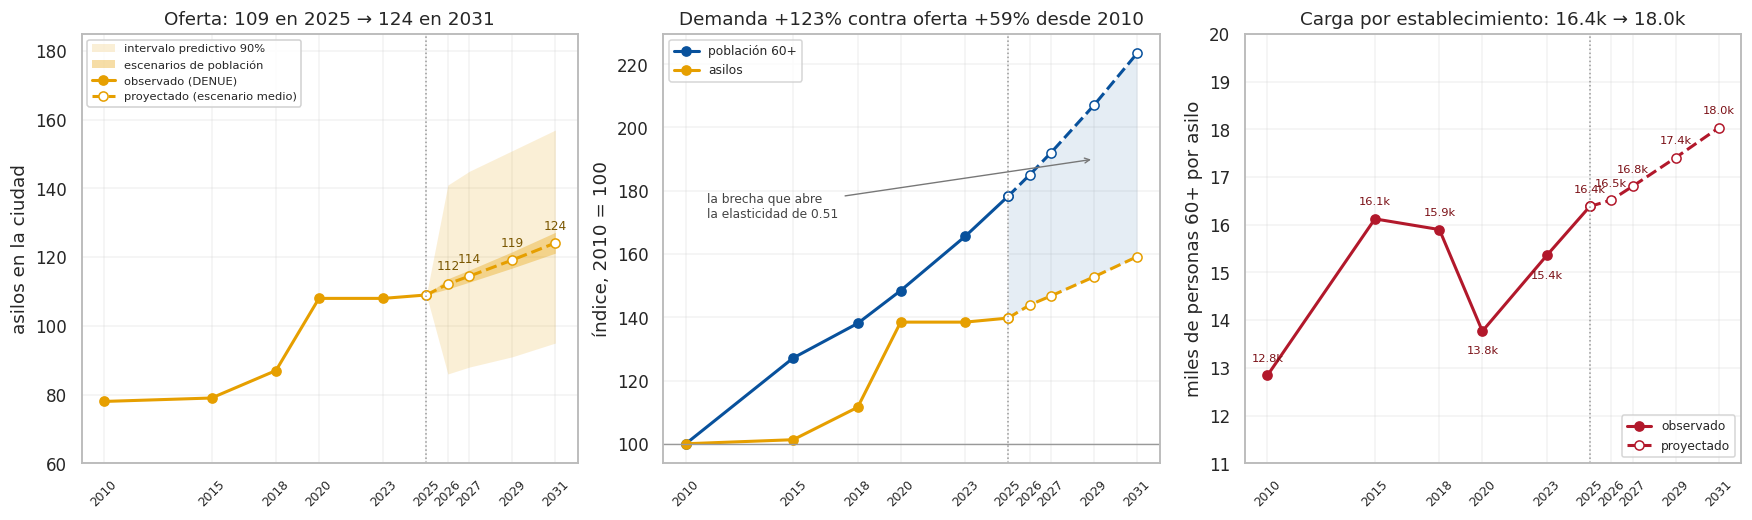

In [15]:
hist_a = ofer.sum()                                   # seis cortes del DENUE
pob_obs = panel.groupby("anio")["p60"].sum()          # censos
hist_p = pd.Series({a: (mod.p60_2020.values*(1 + r_med)**(a - 2020)).sum()
                    if a not in pob_obs.index else pob_obs[a] for a in ANIOS_OF})
pr = pd.DataFrame(filas)
med = pr[pr.escenario == "medio"].set_index("anio")
baj = pr[pr.escenario == "bajo"].set_index("anio")
alt = pr[pr.escenario == "alto"].set_index("anio")
AH, AF = list(ANIOS_OF), [a for a, _ in ANIOS_PRED]
ULT = ANIOS_OF[-1]
PTE = [ULT] + AF
A0 = hist_a[ULT]
AZ, NJ, GR, RJ = "#08519C", "#E69F00", "#999999", "#B2182B"

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))

# 1. nivel de la oferta con incertidumbre
a = ax[0]
a.fill_between(PTE, [A0] + list(med.pred_lo), [A0] + list(med.pred_hi), color=NJ, alpha=.16,
               lw=0, label="intervalo predictivo 90%")
a.fill_between(PTE, [A0] + list(baj.esperados), [A0] + list(alt.esperados), color=NJ, alpha=.35,
               lw=0, label="escenarios de población")
a.plot(AH, hist_a.values, "o-", color=NJ, lw=2, ms=6, label="observado (DENUE)")
a.plot(PTE, [A0] + list(med.esperados), "o--", color=NJ, lw=2, ms=6, mfc="white",
       label="proyectado (escenario medio)")
for x_ in AF:
    a.annotate(f"{med.loc[x_, 'esperados']:.0f}", (x_, med.loc[x_, "esperados"]),
               textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8, color="#7A5600")
a.axvline(ULT, color=GR, ls=":", lw=1)
a.set(ylabel="asilos en la ciudad", xticks=AH + AF, ylim=(60, 185),
      title=f"Oferta: {A0:.0f} en {ULT} → {med.loc[2031, 'esperados']:.0f} en 2031")
a.legend(fontsize=7.5, loc="upper left", framealpha=.9)

# 2. demanda contra oferta, misma escala
b = ax[1]
b.plot(AH, 100*hist_p.values/hist_p[2010], "o-", color=AZ, lw=2, ms=6, label="población 60+")
b.plot(PTE, 100*np.r_[hist_p[ULT], med.pob60.values]/hist_p[2010], "o--", color=AZ, lw=2,
       ms=6, mfc="white")
b.plot(AH, 100*hist_a.values/hist_a[2010], "o-", color=NJ, lw=2, ms=6, label="asilos")
b.plot(PTE, 100*np.r_[A0, med.esperados.values]/hist_a[2010], "o--", color=NJ, lw=2, ms=6,
       mfc="white")
b.fill_between(PTE, 100*np.r_[A0, med.esperados.values]/hist_a[2010],
               100*np.r_[hist_p[ULT], med.pob60.values]/hist_p[2010], color=AZ, alpha=.10, lw=0)
b.annotate("la brecha que abre\nla elasticidad de 0.51", xy=(2029, 190),
           xytext=(2011, 175), fontsize=8, color="#444", ha="left", va="center",
           arrowprops=dict(arrowstyle="->", color="#777", lw=.9))
b.axhline(100, color=GR, lw=.9); b.axvline(ULT, color=GR, ls=":", lw=1)
b.set(ylabel="índice, 2010 = 100", xticks=AH + AF,
      title=f"Demanda +{100*(med.loc[2031,'pob60']/hist_p[2010]-1):.0f}% contra "
            f"oferta +{100*(med.loc[2031,'esperados']/hist_a[2010]-1):.0f}% desde 2010")
b.legend(fontsize=8, loc="upper left")

# 3. qué implica para quien usa el servicio
c = ax[2]
carga_h, carga_f = hist_p.values/hist_a.values, med.pob60.values/med.esperados.values
c.plot(AH, carga_h/1000, "o-", color=RJ, lw=2, ms=6, label="observado")
c.plot(PTE, np.r_[carga_h[-1], carga_f]/1000, "o--", color=RJ, lw=2, ms=6, mfc="white",
       label="proyectado")
for x_, y_ in zip(AH + AF, np.r_[carga_h, carga_f]/1000):
    c.annotate(f"{y_:.1f}k", (x_, y_), textcoords="offset points",
               xytext=(0, -15 if x_ in (2020, 2023) else 9), ha="center", fontsize=7.5,
               color="#7B1016")
c.axvline(ULT, color=GR, ls=":", lw=1)
c.set(ylabel="miles de personas 60+ por asilo", xticks=AH + AF, ylim=(11, 20),
      title=f"Carga por establecimiento: {carga_h[-1]/1000:.1f}k → {carga_f[-1]/1000:.1f}k")
c.legend(fontsize=8, loc="lower right")

for a_ in ax:
    a_.tick_params(axis="x", labelsize=8)
    for t in a_.get_xticklabels(): t.set_rotation(45)
plt.tight_layout(); plt.savefig(FIG/"crecimiento_prediccion.png", dpi=150, bbox_inches="tight")
plt.show()

El panel de en medio es el resumen del análisis: las dos curvas salen del mismo punto en 2020 y se
separan cada año. Esa separación no es un pronóstico pesimista, es aritmética — es lo que significa que
β sea 0.51 y no 1.

El tercer panel traduce eso a la unidad que importa: **de 16.4 mil personas de 60 y más por asilo en
2025 a unas 18 mil en 2031**. Y la serie observada es lo más elocuente: 12.8 mil en 2010, 16.1 mil en
2015, 13.8 mil en 2020 tras el salto de oferta, y de vuelta a 16.4 mil en 2025. **El deterioro no es
una proyección: ya ocurrió dos veces**, cada vez que la oferta se queda quieta unos años mientras la
población sigue creciendo. La proyección solo dice que vuelve a pasar si el mercado se comporta como se
ha comportado.

Una lectura de la banda del primer panel: la franja oscura son los tres escenarios de población y la
clara es el intervalo predictivo completo. Que la oscura sea tan delgada comparada con la clara es la
descomposición de varianza dibujada — la demografía casi no contribuye a la incertidumbre.

## 4. ¿Dónde está el desajuste?

Aquí cambia la pregunta, y conviene ser explícito sobre por qué. La sección 3 dice cuántos asilos
habrá; ésta dice **cómo se reparte esa oferta frente a dónde está creciendo la demanda**.

**Una aclaración conceptual que decide todo lo que sigue.** Un asilo no es un servicio al que uno va y
regresa: **es un lugar donde uno se queda**. La persona que entra a un asilo en Coyoacán viniendo de
Iztapalapa ya no vive en Iztapalapa. Eso descarta el instrumento habitual para estas preguntas —los
métodos de área de captación tipo 2SFCA, diseñados para clínicas y farmacias, donde la distancia desde
tu casa es la fricción que te impide usar el servicio—. Se probaron y se descartaron: con un radio de
2 km salían 740 AGEBs sin cobertura y con 5 km salían 69, y el orden de las alcaldías se volteaba entre
uno y otro. El radio no es un parámetro que se afina: **es la definición de qué cuenta como accesible**,
y elegirlo por conveniencia es elegir la respuesta.

Lo que sí se puede medir sin inventarse un umbral es **la aritmética del desajuste**: cuánta demanda
nueva le toca a cada establecimiento que ya existe. Eso no depende de ninguna distancia.

Y hay una cosa que estos datos **no** pueden contestar, y conviene decirla de una vez: si una persona
concreta consigue una cama. Para eso lo que manda es la capacidad total de la ciudad —alguien dispuesto
a mudarse compite por camas en todos lados, no en su colonia— y **el DENUE no trae número de camas**.
Un asilo de 8 pesa igual que uno de 80 en todo lo que sigue.

### 4.1 La aritmética del desajuste

In [16]:
terr = mod.copy()
terr["p60_2031"] = p31
terr["asilos"] = terr.asilos_2025                 # oferta vigente: último corte del DENUE

T = terr.groupby("nom_mun").agg(p60_2020=("p60_2020", "sum"), p60_2031=("p60_2031", "sum"),
                                asilos=("asilos", "sum"))
T["nuevos"] = T.p60_2031 - T.p60_2020
T["crec_%"] = 100*(T.p60_2031/T.p60_2020 - 1)
T["por_10mil_2025"] = 1e4*T.asilos/T.p60_2020
T["por_10mil_2031"] = 1e4*T.asilos/T.p60_2031
T["nuevos_por_asilo"] = np.where(T.asilos > 0, T.nuevos/T.asilos, np.nan)
T["pers_por_asilo_2031"] = np.where(T.asilos > 0, T.p60_2031/T.asilos, np.nan)

print(T.sort_values("nuevos_por_asilo", ascending=False).round(1).to_string())
c = T.dropna()
print(f"\nCiudad: {T.nuevos.sum():,.0f} personas de 60+ nuevas entre 2020 y 2031 repartidas entre "
      f"{T.asilos.sum():.0f} asilos = {T.nuevos.sum()/T.asilos.sum():,.0f} nuevas por establecimiento")
print(f"Oferta por cada 10 mil personas de 60+: {1e4*T.asilos.sum()/T.p60_2020.sum():.2f} hoy → "
      f"{1e4*T.asilos.sum()/T.p60_2031.sum():.2f} en 2031 si la oferta no crece")
print(f"Desigualdad entre alcaldías: {c.nuevos_por_asilo.max()/c.nuevos_por_asilo.min():.1f}x en demanda "
      f"nueva por asilo | {c.pers_por_asilo_2031.max()/c.pers_por_asilo_2031.min():.1f}x en carga a 2031")
print(f"Alcaldías sin un solo establecimiento: "
      f"{', '.join(T.index[T.asilos == 0])} ({T.loc[T.asilos == 0, 'nuevos'].sum():,.0f} personas nuevas)")

                        p60_2020  p60_2031  asilos    nuevos  crec_%  por_10mil_2025  por_10mil_2031  nuevos_por_asilo  pers_por_asilo_2031
nom_mun                                                                                                                                    
Iztacalco                70906.0  107351.2       2   36445.2    51.4             0.3             0.2           18222.6              53675.6
Tláhuac                  45684.0   81212.1       2   35528.1    77.8             0.4             0.2           17764.0              40606.0
Iztapalapa              262062.0  410251.4      10  148189.4    56.5             0.4             0.2           14818.9              41025.1
Venustiano Carranza      78964.0  107134.0       2   28170.0    35.7             0.3             0.2           14085.0              53567.0
Cuajimalpa de Morelos    25458.0   50875.4       3   25417.4    99.8             1.2             0.6            8472.5              16958.5
Azcapotzalco        

**La cifra que resume el problema: 752 mil personas de 60 y más nuevas entre 2020 y 2031, repartidas
entre 108 establecimientos — casi 7 mil nuevas por cada asilo que ya existe.** Y muy desigualmente:
Iztacalco, Tláhuac, Iztapalapa y Venustiano Carranza reciben entre 14 mil y 18 mil personas nuevas por
asilo existente, contra 2,758 de Benito Juárez. **Una diferencia de 6.6 veces**, sin que intervenga
ninguna definición de distancia.

Si la oferta no creciera nada, en 2031 habría una persona de 60+ por cada 10,698 en Benito Juárez y
53,676 en Iztacalco: **cinco veces la carga**. Y Milpa Alta suma 12 mil personas mayores nuevas sobre
**cero** establecimientos, un caso que ni siquiera admite razón.

Vale la pena ver cómo se ve eso en el mapa, junto a lo que la sección 3.2 ya había estimado.

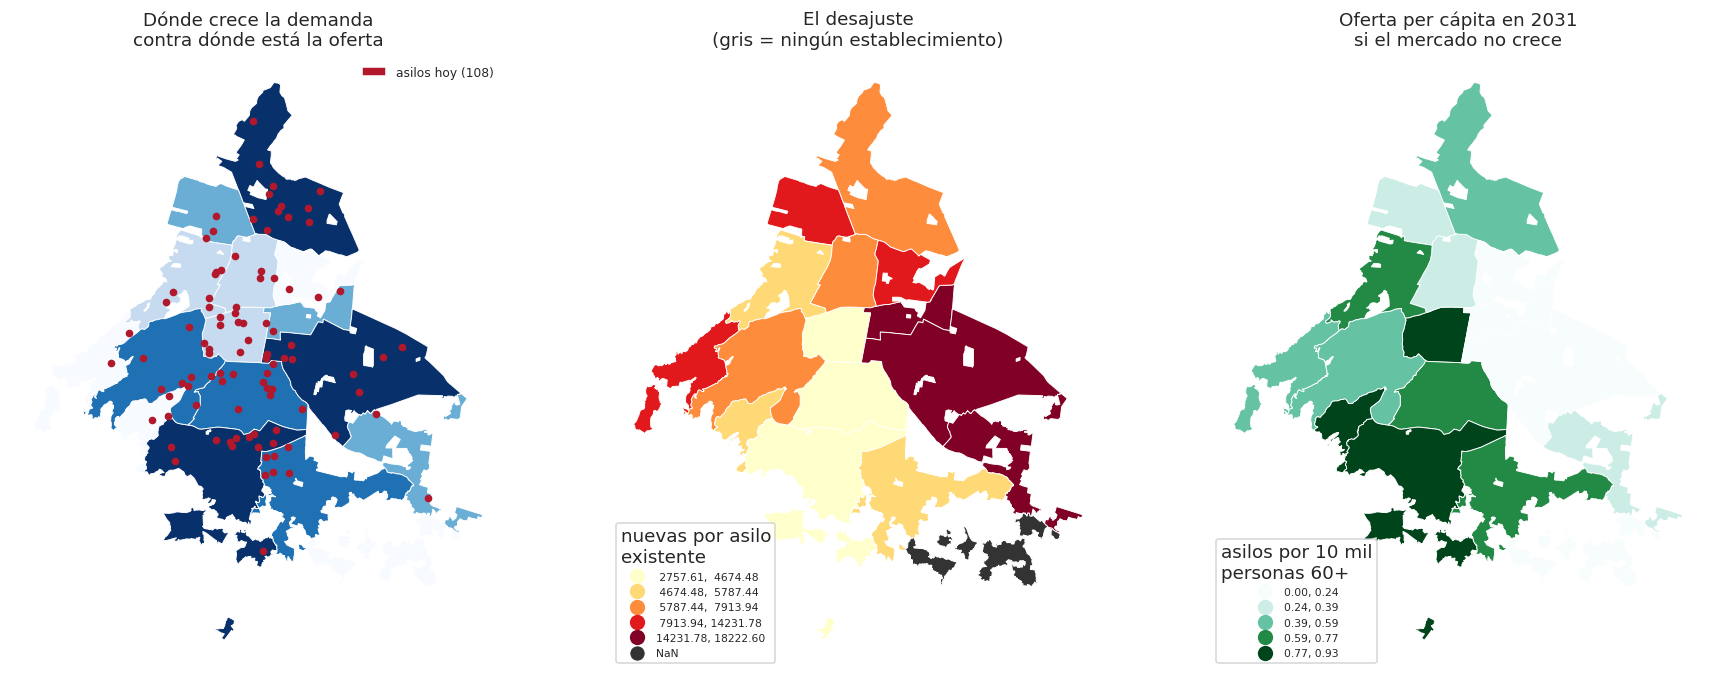

tabla por alcaldía en desajuste_por_alcaldia.csv


In [17]:
mapa_t = terr[["nom_mun", "geometry"]].dissolve(by="nom_mun").join(T)
fig, ax = plt.subplots(1, 3, figsize=(16.5, 6.2))

mapa_t.plot(column="nuevos", cmap="Blues", scheme="quantiles", k=5, ax=ax[0], legend=True,
            edgecolor="white", linewidth=.6,
            legend_kwds={"fontsize": 7, "loc": "lower left", "title": "personas 60+ nuevas\n2020→2031"})
oferta_p = terr[terr.asilos > 0]
oferta_p.centroid.plot(ax=ax[0], color="#B2182B", markersize=16)
ax[0].legend(handles=[Patch(facecolor="#B2182B", label=f"asilos hoy ({int(T.asilos.sum())})")],
             loc="upper right", frameon=False, fontsize=8)
ax[0].set_title("Dónde crece la demanda\ncontra dónde está la oferta")

mapa_t.plot(column="nuevos_por_asilo", cmap="YlOrRd", scheme="quantiles", k=5, ax=ax[1], legend=True,
            edgecolor="white", linewidth=.6, missing_kwds={"color": "#333333"},
            legend_kwds={"fontsize": 7, "loc": "lower left", "title": "nuevas por asilo\nexistente"})
ax[1].set_title("El desajuste\n(gris = ningún establecimiento)")

mapa_t.plot(column="por_10mil_2031", cmap="BuGn", scheme="quantiles", k=5, ax=ax[2], legend=True,
            edgecolor="white", linewidth=.6,
            legend_kwds={"fontsize": 7, "loc": "lower left", "title": "asilos por 10 mil\npersonas 60+"})
ax[2].set_title("Oferta per cápita en 2031\nsi el mercado no crece")
for a_ in ax: a_.set_axis_off()
plt.tight_layout(); plt.savefig(FIG/"desajuste_territorial.png", dpi=150, bbox_inches="tight")
plt.show()
T.round(2).to_csv("desajuste_por_alcaldia.csv")
print("tabla por alcaldía en desajuste_por_alcaldia.csv")

El primer mapa es el análisis entero en una imagen: los puntos rojos se apiñan en el centro-poniente
mientras el azul oscuro —las personas de 60 y más que se suman en la década— se concentra en Iztapalapa
y la periferia sur y oriente. **La oferta está donde estuvo la demanda, no donde va a estar.**

## 5. Conclusiones y limitaciones

**Lo que se sostiene:**

1. La población de 60+ creció 48% en una década y crecerá 43-58% más hacia 2031, concentrando el
   crecimiento en la periferia sur y poniente. Esto está validado en backtest (R² 0.94, MAPE 10%) y
   encoger la tasa de cada AGEB hacia la de su alcaldía gana contra todas las alternativas probadas.
   **La oferta, en cambio, se detuvo:** 108 asilos en 2020 y 109 en 2025, con la población creciendo
   20% en ese lapso.
2. La elasticidad oferta-población es 0.51 [0.10, 0.92], menor que 1: **la oferta crece a la mitad del
   ritmo de la demanda demográfica**. Estimada sobre los seis cortes del DENUE, con efectos por corte
   y errores agrupados por AGEB. Se proyectan 124 asilos para 2031 [95, 157] contra 109 hoy, y el
   jerárquico por regiones Ward coincide con 122 [97, 149].
3. Hay heterogeneidad territorial real más allá de población y área (σ_α claramente > 0), en dirección
   socioeconómica. El nivel de agrupación no se eligió a ojo: Ward k=40 gana la validación cruzada
   espacial contra alcaldías y contra particiones más finas.
4. **El desajuste territorial, medido sin supuestos de distancia:** 752 mil personas de 60 y más
   nuevas entre 2020 y 2031 repartidas entre 108 establecimientos —casi 7 mil por asilo existente— con
   **6.6x de diferencia entre alcaldías**. Iztacalco, Tláhuac, Iztapalapa y Venustiano Carranza reciben
   entre 14 y 18 mil nuevas por asilo; Benito Juárez, 2,758. Milpa Alta suma 12 mil sobre cero
   establecimientos.
5. La oferta per cápita de la ciudad pasa de **0.73 a 0.48 asilos por cada diez mil personas de 60+**
   si el mercado crece como se proyecta, con 5.5x de desigualdad entre alcaldías.

**Lo que no se sostiene, y conviene decirlo antes de que alguien lo pida:**

- **Predecir cuántos asilos habrá en un AGEB específico.** El poder predictivo a ese nivel es débil y el
  techo alcanzable con estas covariables es apenas 13% del rango entre no saber nada y predecir
  perfecto.
- **Medir acceso individual a un asilo.** Un asilo es residencial: quien entra se muda. Los métodos de
  área de captación (2SFCA y similares) están diseñados para servicios ambulatorios y no aplican aquí;
  se probaron y se descartaron por eso, no por un problema técnico. La sección 4 lo explica.
- **Decir cuántos asilos "deberían" existir en una zona, o si alguien conseguirá cama.** No hay norma
  de camas por cada mil adultos mayores en México y **el DENUE no trae capacidad**: un asilo de 8 camas
  pesa igual que uno de 80. Ésa es la limitación más seria de toda la sección 4.
- **Afirmar hacia dónde se está moviendo el mercado.** Se revisaron las aperturas netas por alcaldía
  entre 2010 y 2025 y no hay patrón significativo en ninguna dirección: ni hacia las zonas de mayor
  ingreso —Benito Juárez perdió 5 establecimientos y Cuauhtémoc 5, mientras Tlalpan ganó 9— ni hacia
  donde crece la población (Spearman +0.38, p = 0.14). **El mapa de propensión es un enunciado de
  nivel, no de dinámica.**
- **Poner una cifra precisa al total.** El intervalo para 2031 sigue midiendo más de 60 asilos. La
  dirección sí; la magnitud no.
- **Cualquier afirmación sobre enfermería a domicilio.** La serie va de 17 a 8 establecimientos con
  saltos sin sentido, la autocorrelación espacial es nula, y el AGEB es la unidad equivocada para un
  servicio a domicilio.
- **Leer la proyección como necesidad.** Es "cuántos habrá si nada cambia", no "cuántos se necesitan".

**Limitaciones de los datos:**

- 2015 es estimación de encuesta, con error de muestreo que contamina las tasas por quinquenio.
- **Los cortes del DENUE no son plenamente comparables.** El salto de 2018 a 2020 (+21 asilos) y la
  quietud de 2020 a 2023 (cero neto) sugieren reclasificación o re-geocodificación entre extracciones.
  El modelo lo absorbe con efectos por corte, pero eso limita cuánto se puede leer del movimiento
  AGEB por AGEB entre un corte y otro. La serie de enfermería (17 → 26 → 26 → 12 → 13 → 8) es el caso
  extremo del mismo problema.
- Las proyecciones usan tasas observadas en vez de CONAPO. Aunque, como mostró la descomposición de
  varianza, anclarlas a CONAPO mejoraría poco el pronóstico de servicios.
- **Falta el número de camas.** Es la mejora que más cambiaría el análisis: convertiría "asilos por
  cada diez mil personas" en una medida de capacidad real y haría respondible la pregunta de
  suficiencia.
- **Faltan covariables socioeconómicas.** El patrón de niveles por alcaldía apunta al ingreso como
  determinante de la ubicación de la oferta, pero sin el índice de marginación por AGEB eso es
  hipótesis, no resultado.

**Qué se probó y quedó fuera** (está en `analisis_agebs_cdmx_v3.ipynb`, el notebook de trabajo):

| Se probó | Qué mostró | Por qué no está aquí |
|---|---|---|
| Agrupar AGEBs (Ward con contigüidad, k-means, hexágonos, alcaldía) | Agregar gana **precisión** en β, no identificación | El AGEB es la resolución máxima; la precisión se ganó apilando cortes, no agregando unidades |
| Sensibilidad a la agrupación (MAUP) | β es estable entre agrupaciones; el error estándar sí cambia | Confirmó la decisión, no la cambió |
| Validación cruzada espacial de los niveles de agrupación del jerárquico | Ward k=40 gana; el LOO engaña con efectos espaciales | Su conclusión **sí** se usa: es la que eligió la agrupación de la sección 3.2 |
| Validación cruzada espacial por bloques | Todos los modelos mejoran poco sobre el nulo; el techo es 13% | Su conclusión está citada en el punto sobre poder predictivo |
| Accesibilidad 2SFCA, banderas 1/0 y listas por AGEB | El resultado depende del radio: 740 AGEBs descubiertos con 2 km, 69 con 5 km, y el orden de alcaldías se voltea | El instrumento no corresponde a un servicio residencial (sección 4) |
| Prueba de si se puede anticipar dónde abrirá un asilo | La regla de población más cobertura cae dentro del rango de azar (lift 0.97) | Dependía del radio; su parte útil —que la población sola predice— está en la sección 4.2 |
| Poisson simple, zero-inflated, Random Forest, efectos fijos, SAR | Ninguno gana; el bosque ordena mejor (AUC 0.68) pero sobreestima el total 16% | Dos modelos bastan y se anidan entre sí |

**Siguiente paso natural:** incorporar marginación o nivel socioeconómico por AGEB, y para un análisis
de accesibilidad más fino, pasar de radio euclidiano a tiempos de traslado por red vial.